<a href="https://www.kaggle.com/code/avikdas567/wasserstein-1-soil-granulometry-via-dual-scale-mil?scriptVersionId=374259154" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Quantitative Granulometry from Surface Photographs: Scale-Calibrated Multi-Modal Learning for Soil Grain Size Distribution Prediction

---

## Abstract

Determining the cumulative grain size distribution (GSD) of soil samples according to **DIN EN ISO 14688-1** traditionally requires labor-intensive sieve and sedimentation (hydrometer) analyses. This study presents an end-to-end, physics-calibrated computer vision and geotechnical machine learning pipeline to predict the 11-point cumulative mass fraction curve $F(d)$ across $d \in \{0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2.0, 6.3, 20.0, 63.0, 200.0\}\text{ mm}$ directly from multi-view surface photographs.

A central metrological finding of our dataset audit is a pronounced **cross-camera resolution and ISP domain shift**: training photographs were acquired with downscaled Motorola Edge and Samsung A52 sensors ($\text{PPM}_{\text{eff}} \approx 4.56\text{--}12.47\text{ px/mm}$), whereas test photographs were acquired with full-resolution iPhone 14 and iPhone 16 sensors ($\text{PPM}_{\text{eff}} = 13.94\text{--}19.53\text{ px/mm}$). Without explicit physical scale normalization, a $2\text{ mm}$ sand grain spans more than $4\times$ the pixel area in test images relative to training images. We resolve this by computing the exact effective pixel-per-millimeter ($\text{PPM}_{\text{eff}}$) for each photograph and resampling all imagery to canonical physical resolutions ($4.5\text{ px/mm}$ and $1.5\text{ px/mm}$).

Our modeling architecture combines four complementary paradigms:
1. **Virtual Granulometric Sieving & Spectral Physics**: Multi-scale mathematical morphology (disk-opening granulometry), 2D isotropic Fast Fourier Transform (FFT) radial power spectra mapped to physical wavelengths ($\text{mm}$), rotation-invariant Local Binary Patterns (LBP), Gray-Level Co-occurrence Matrices (GLCM), and CIE-$L^*a^*b^*$ colorimetric descriptors.
2. **Foundation Vision Embeddings with Attention-MIL**: Multi-scale physical-patch representations extracted from frozen `ConvNeXt` and `DINOv2` backbones, aggregated across variable numbers of sample photographs via gated Multiple Instance Learning (MIL) and trained directly against the differentiable Wasserstein-1 (Earth Mover's Distance, EMD) objective.
3. **End-to-End Domain-Invariant Fine-Tuning**: Fine-tuned `ConvNeXt-Tiny` with photometric ISP-shift augmentations and a monotonic softmax-increment output head.
4. **Constrained Simplex Ensemble Optimization**: Non-negative convex combination of out-of-fold (OOF) predictions optimized directly for the competition's logarithmically weighted EMD metric under strict monotonicity and boundary constraints ($0 \le F_1 \le \dots \le F_{10} \le F_{11} = 100$).

# 1. Mathematical Formulation and Competition Metric

## 1.1 DIN EN ISO 14688-1 Support Points and Monotonicity

Let $\mathbf{x} = (x_1, x_2, \dots, x_{11})$ denote the eleven standardized grain diameters in millimeters:
$$\mathbf{x} = (0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2.0, 6.3, 20.0, 63.0, 200.0)$$

For any soil sample $s$, the cumulative mass fraction $F_i \in [0, 100]$ represents the percentage of dry soil mass passing sieve diameter $x_i$. By physical conservation of mass, $F$ satisfies:
$$0 \le F_1 \le F_2 \le \dots \le F_{10} \le F_{11} = 100$$

Rather than regressing $F_1, \dots, F_{10}$ independently (which risks monotonicity violations), we parameterize the distribution via its non-negative bin mass increments $\mathbf{p} = (p_1, \dots, p_{11}) \in \Delta^{10}$ on the $100$-scaled probability simplex:
$$p_k \ge 0, \quad \sum_{k=1}^{11} p_k = 100, \quad F_i = \sum_{k=1}^{i} p_k$$

In neural architectures, this is enforced identically by construction via a softmax parameterization $p_k = 100 \cdot \frac{\exp(z_k)}{\sum_{j=1}^{11} \exp(z_j)}$ followed by cumulative summation.

## 1.2 Logarithmically Weighted Earth Mover's Distance (Wasserstein-1)

The evaluation metric is the area between the true and predicted cumulative grading curves on a $\log_{10}(d)$ abscissa:
$$\text{EMD}(F, \hat{F}) = \sum_{i=1}^{10} \left| F_i - \hat{F}_i \right| \cdot \Delta_i, \qquad \Delta_i = \log_{10}(x_{i+1}) - \log_{10}(x_i)$$

Because $\sum_{i=1}^{10} \Delta_i = \log_{10}(200 / 0.002) = 5.0$, the metric is bounded in $[0, 500]$, where $\text{EMD} = 0$ indicates exact agreement across all support points. Notice that each logarithmic interval width $\Delta_i \approx 0.50$, giving equal geometric weight to fine clay/silt fractions and coarse gravel fractions.

## 1.3 Physical Scale Calibration ($\text{PPM}_{\text{eff}}$)

Camera metadata provides native sensor dimensions $(W_{\text{native}}, H_{\text{native}})$ and calibrated pixel-per-millimeter resolution $\text{PPM}_{\text{native}}$. When an image has been resized to $(W_{\text{img}}, H_{\text{img}})$, the effective physical resolution is:
$$\text{PPM}_{\text{eff}} = \text{PPM}_{\text{native}} \cdot \frac{\max(W_{\text{img}}, H_{\text{img}})}{\max(W_{\text{native}}, H_{\text{native}})}$$

Resampling every photograph by scale factor $s = \text{PPM}_{\text{target}} / \text{PPM}_{\text{eff}}$ guarantees that a physical grain of diameter $d\text{ mm}$ subtends exactly $d \cdot \text{PPM}_{\text{target}}$ pixels across all camera sensors.

In [1]:
import os
import sys
import gc
import re
import math
import glob
import time
import random
import logging
import warnings
import unicodedata
from pathlib import Path

os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

warnings.filterwarnings("ignore")
for logger_name in ["transformers", "timm", "albumentations", "PIL", "matplotlib", "lightgbm"]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import scipy
from scipy import ndimage, optimize, stats
from sklearn.isotonic import IsotonicRegression
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.morphology import disk, opening

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, HuberRegressor, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import ExtraTreesRegressor

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
import timm
import lightgbm as lgb

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
    "legend.framealpha": 0.9
})

DATA_ROOT = Path("/kaggle/input/competitions/soil-grain-size-from-photos")
if not DATA_ROOT.exists():
    DATA_ROOT = Path("soil-grain-size-from-photos")

DIAMETERS = np.array([0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2.0, 6.3, 20.0, 63.0, 200.0], dtype=np.float64)
TARGET_COLS = ["0.002", "0.0063", "0.02", "0.063", "0.2", "0.63", "2", "6.3", "20", "63", "200"]
LOG_DIAMETERS = np.log10(DIAMETERS)
INTERVAL_WEIGHTS = np.diff(LOG_DIAMETERS)

print(f"PyTorch: {torch.__version__} | Device: {DEVICE} | GPUs: {N_GPUS}")
print(f"Dataset root: {DATA_ROOT} (exists={DATA_ROOT.exists()})")
print(f"Interval log10 weights: {np.round(INTERVAL_WEIGHTS, 5)} | Sum: {INTERVAL_WEIGHTS.sum():.5f}")

PyTorch: 2.11.0+cu130 | Device: cuda | GPUs: 2
Dataset root: /kaggle/input/competitions/soil-grain-size-from-photos (exists=True)
Interval log10 weights: [0.49831 0.50169 0.49831 0.50169 0.49831 0.50169 0.49831 0.50169 0.49831
 0.50169] | Sum: 5.00000


# 2. Data Ingestion, Identifier Normalization, and Camera Metrology

We load the training labels (`Training_labels_updated.csv`), camera calibration table (`ppm_updated.csv`), and submission template (`sample_submission.csv`). Note two critical data engineering details discovered during inspection:
1. **Filename-to-ID Normalization**: Test filenames contain German umlauts and comma decimal separators (e.g., `iPhone14_HPC_Münster_BS6_9,0-10m (1).JPG`), whereas `sample_submission.csv` uses ASCII transliterations and underscores (`HPC_Muenster_BS6_9_0-10m`). We implement a deterministic normalization map to guarantee 100% photo-to-sample matching.
2. **Effective PPM Calculation**: Training images from `Motorola_Edge` and `Samsung_A52` were stored at reduced pixel dimensions relative to their native sensor dimensions in `ppm_updated.csv`. Computing $\text{PPM}_{\text{eff}}$ reconciles this discrepancy.

In [2]:
def find_csv_file(root_dir, candidates):
    for name in candidates:
        p = root_dir / name
        if p.exists():
            return p
    raise FileNotFoundError(f"None of {candidates} found under {root_dir}")

def find_image_files(root_dir, folder_candidates):
    for name in folder_candidates:
        base = root_dir / name
        if base.exists():
            files = []
            for ext in ("*.jpg", "*.JPG", "*.jpeg", "*.JPEG", "*.png", "*.PNG"):
                files.extend(base.rglob(ext))
            if files:
                return sorted(set(files))
    raise FileNotFoundError(f"No images found in {folder_candidates} under {root_dir}")

train_csv = find_csv_file(DATA_ROOT, ["Training_labels_updated.csv", "train.csv"])
ppm_csv = find_csv_file(DATA_ROOT, ["ppm_updated.csv", "ppm.csv"])
sub_csv = find_csv_file(DATA_ROOT, ["sample_submission.csv"])

train_df = pd.read_csv(train_csv)
ppm_df = pd.read_csv(ppm_csv)
sub_df = pd.read_csv(sub_csv)

train_img_paths = find_image_files(DATA_ROOT, ["Training-All_Photos_updated", "All_Photos_training"])
test_img_paths = find_image_files(DATA_ROOT, ["Test_All_Photos", "All_Photos_test"])

def normalize_token(text):
    text = text.replace("ü", "ue").replace("ä", "ae").replace("ö", "oe")
    text = text.replace("Ü", "Ue").replace("Ä", "Ae").replace("Ö", "Oe").replace("ß", "ss")
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]", "", text.lower())

def match_camera_row(filename, ppm_table):
    fn_low = filename.lower()
    if "edge_60_fusion" in fn_low or "edge 60 fusion" in fn_low:
        row = ppm_table[ppm_table["phone"].str.contains("60 Fusion", case=False)].iloc[0]
    elif "motorola" in fn_low:
        row = ppm_table[ppm_table["phone"].str.strip().str.lower() == "motorola edge"].iloc[0]
    elif "samsung" in fn_low or "a52" in fn_low:
        row = ppm_table[ppm_table["phone"].str.contains("Samsung", case=False)].iloc[0]
    elif "iphone14" in fn_low or "iphone 14" in fn_low:
        row = ppm_table[ppm_table["phone"].str.contains("14", case=False)].iloc[0]
    elif "iphone16" in fn_low or "iphone" in fn_low:
        row = ppm_table[ppm_table["phone"].str.contains("16", case=False)].iloc[0]
    else:
        raise ValueError(f"Unrecognized camera prefix in filename: {filename}")
    return row

def build_image_manifest(img_paths, sample_ids, ppm_table, split_name):
    norm_id_map = {normalize_token(sid): sid for sid in sample_ids}
    sorted_keys = sorted(norm_id_map.keys(), key=len, reverse=True)
    records = []
    for p in img_paths:
        fn = p.name
        fn_norm = normalize_token(fn)
        matched_sid = None
        for k in sorted_keys:
            if k in fn_norm:
                matched_sid = norm_id_map[k]
                break
        if matched_sid is None:
            raise ValueError(f"Could not match sample_id for {fn}")
        with Image.open(p) as im:
            im_exif = ImageOps.exif_transpose(im)
            w, h = im_exif.size
        cam_row = match_camera_row(fn, ppm_table)
        native_long = max(float(cam_row["width"]), float(cam_row["height"]))
        actual_long = max(float(w), float(h))
        scale_ratio = actual_long / native_long
        eff_ppm = float(cam_row["ppm"]) * scale_ratio
        records.append({
            "split": split_name,
            "sample_id": matched_sid,
            "path": str(p),
            "filename": fn,
            "camera_model": cam_row["phone"],
            "width": w,
            "height": h,
            "native_ppm": float(cam_row["ppm"]),
            "scale_ratio": scale_ratio,
            "eff_ppm": eff_ppm,
            "fov_width_mm": w / eff_ppm,
            "fov_height_mm": h / eff_ppm
        })
    return pd.DataFrame(records)

train_manifest = build_image_manifest(train_img_paths, train_df["sample_id"].tolist(), ppm_df, "train")
test_manifest = build_image_manifest(test_img_paths, sub_df["sample_id"].tolist(), ppm_df, "test")
full_manifest = pd.concat([train_manifest, test_manifest], ignore_index=True)

print(f"Training samples: {len(train_df)} | Training images: {len(train_manifest)}")
print(f"Test samples:     {len(sub_df)} | Test images:     {len(test_manifest)}")
print("\nCamera Metrology Summary:")
summary_cam = full_manifest.groupby(["split", "camera_model", "width", "height"]).agg(
    n_images=("filename", "count"),
    n_samples=("sample_id", "nunique"),
    native_ppm=("native_ppm", "first"),
    eff_ppm=("eff_ppm", "first"),
    fov_w_mm=("fov_width_mm", "mean")
).reset_index()
display(summary_cam)

Training samples: 24 | Training images: 127
Test samples:     10 | Test images:     35

Camera Metrology Summary:


,split,camera_model,width,height,n_images,n_samples,native_ppm,eff_ppm,fov_w_mm
0,test,iPhone 14,3024,4032,13,3,13.942,13.942000,216.898580
1,test,iPhone 14,4032,3024,1,1,13.942,13.942000,289.198106
2,test,iPhone 16,4284,5712,18,6,19.525,19.525000,219.411012
3,test,iPhone 16,5712,4284,3,1,19.525,19.525000,292.548015
4,train,Motorola Edge,720,1600,25,18,11.492,4.596800,156.630700
5,train,Motorola Edge,1600,720,44,20,11.492,4.596800,348.068221
6,train,Motorola Edge 60 Fusion,2304,4096,1,1,12.465,12.465000,184.837545
7,train,Motorola Edge 60 Fusion,4096,2304,2,1,12.465,12.465000,328.600080
8,train,Samsung A52,1599,1200,55,22,26.330,4.552516,351.234333


# 3. Exact Competition Metric and Geotechnical Index Computation

We define the exact numpy and PyTorch implementations of the logarithmically weighted Earth Mover's Distance (EMD), verify the trivial uniform baseline score reported in the competition description, and compute classical geotechnical grading parameters from each training curve:
- Characteristic diameters $D_{10}, D_{30}, D_{50}, D_{60}$ via log-linear interpolation.
- Coefficient of Uniformity $C_u = D_{60} / D_{10}$ and Coefficient of Curvature $C_c = D_{30}^2 / (D_{10} \cdot D_{60})$.
- Mass fractions by DIN EN ISO 14688-1 soil classes: Clay ($<0.002\text{ mm}$), Silt ($0.002\text{--}0.063\text{ mm}$), Sand ($0.063\text{--}2.0\text{ mm}$), and Gravel ($2.0\text{--}63.0\text{ mm}$).

In [3]:
def compute_emd_sample(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return float(np.sum(np.abs(y_true[:10] - y_pred[:10]) * INTERVAL_WEIGHTS))

def compute_emd_batch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return float(np.mean(np.sum(np.abs(y_true[:, :10] - y_pred[:, :10]) * INTERVAL_WEIGHTS[None, :], axis=1)))

def project_monotonic_curve(y):
    y = np.asarray(y, dtype=np.float64).copy()
    if y.ndim == 1:
        y = np.clip(y, 0.0, 100.0)
        iso = IsotonicRegression(y_min=0.0, y_max=100.0, increasing=True)
        y_proj = iso.fit_transform(np.arange(11), y)
        y_proj[-1] = 100.0
        return y_proj
    out = np.zeros_like(y)
    for i in range(y.shape[0]):
        out[i] = project_monotonic_curve(y[i])
    return out

def interpolate_dx(curve, target_pct):
    curve = np.asarray(curve, dtype=np.float64)
    if curve[0] >= target_pct:
        return DIAMETERS[0]
    if curve[-1] <= target_pct:
        return DIAMETERS[-1]
    idx = np.searchsorted(curve, target_pct, side="right") - 1
    idx = max(0, min(idx, 9))
    f0, f1 = curve[idx], curve[idx + 1]
    if f1 <= f0 + 1e-12:
        return DIAMETERS[idx]
    frac = (target_pct - f0) / (f1 - f0)
    log_d = LOG_DIAMETERS[idx] + frac * (LOG_DIAMETERS[idx + 1] - LOG_DIAMETERS[idx])
    return float(10.0 ** log_d)

Y_train = train_df[TARGET_COLS].values.astype(np.float64)
uniform_baseline = np.linspace(100.0 / 11.0, 100.0, 11)
uniform_preds = np.tile(uniform_baseline, (len(Y_train), 1))
mean_curve = np.mean(Y_train, axis=0)
mean_preds = np.tile(mean_curve, (len(Y_train), 1))

print(f"Trivial Uniform Baseline OOF EMD: {compute_emd_batch(Y_train, uniform_preds):.4f}")
print(f"Constant Training-Mean Curve EMD: {compute_emd_batch(Y_train, mean_preds):.4f}")

geotech_rows = []
for idx, row in train_df.iterrows():
    c = row[TARGET_COLS].values.astype(np.float64)
    d10 = interpolate_dx(c, 10.0)
    d30 = interpolate_dx(c, 30.0)
    d50 = interpolate_dx(c, 50.0)
    d60 = interpolate_dx(c, 60.0)
    cu = d60 / max(d10, 1e-4)
    cc = (d30 ** 2) / max(d10 * d60, 1e-8)
    clay = c[0]
    silt = c[3] - c[0]
    sand = c[6] - c[3]
    gravel = c[9] - c[6]
    geotech_rows.append({
        "sample_id": row["sample_id"],
        "D10_mm": d10,
        "D30_mm": d30,
        "D50_mm": d50,
        "D60_mm": d60,
        "Cu": cu,
        "Cc": cc,
        "Clay_pct": clay,
        "Silt_pct": silt,
        "Sand_pct": sand,
        "Gravel_pct": gravel
    })
geotech_df = pd.DataFrame(geotech_rows)
print("\nGeotechnical Summary of Training Dataset:")
display(geotech_df.describe().T[["mean", "std", "min", "50%", "max"]].round(4))

Trivial Uniform Baseline OOF EMD: 102.0235
Constant Training-Mean Curve EMD: 86.1435

Geotechnical Summary of Training Dataset:


,mean,std,min,50%,max
D10_mm,0.0894,0.1146,0.0020,0.0260,0.3416
D30_mm,0.7982,0.9326,0.0077,0.2380,2.6928
D50_mm,2.1225,2.2632,0.0213,1.3046,6.1261
D60_mm,3.2930,3.4319,0.0281,2.0439,9.4142
Cu,53.2559,69.8000,3.4978,17.5789,281.5634
Cc,2.0478,1.4461,0.5281,1.5248,5.8089
Clay_pct,3.0507,4.1105,0.0000,1.1824,17.7068
Silt_pct,27.1783,25.2600,0.8232,14.6170,80.0650
Sand_pct,34.5192,18.8493,10.4446,28.1445,95.5415
Gravel_pct,34.7665,31.4696,0.0000,42.1710,77.2376


# 4. Exploratory Data Analysis: Granulometry and Camera Metrology

We visualize the geotechnical structure of the 24 training soils and the physical resolution distribution across sensors.

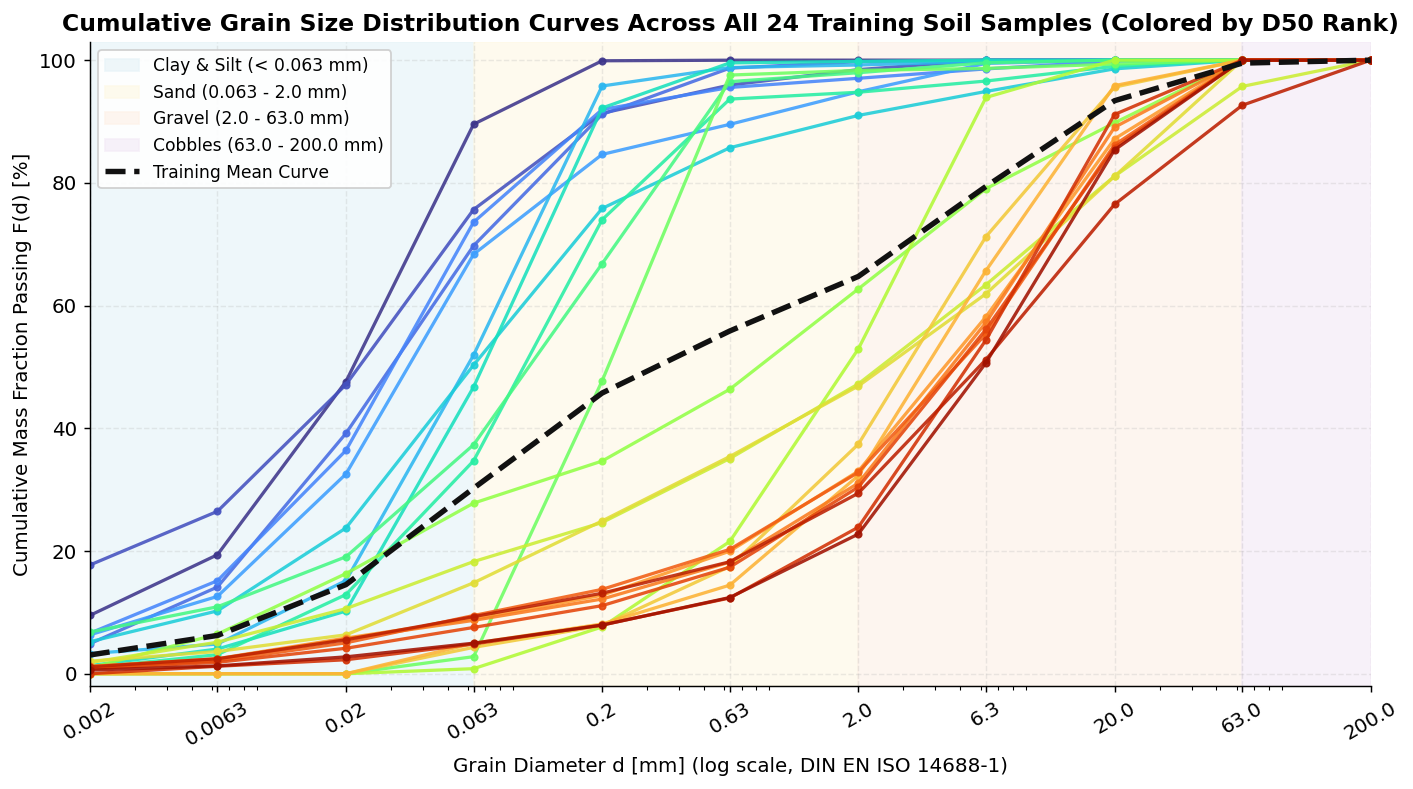

In [4]:
fig, ax = plt.subplots(figsize=(11, 6.2))
palette = plt.cm.turbo(np.linspace(0.05, 0.95, len(Y_train)))
order_d50 = np.argsort(geotech_df["D50_mm"].values)

ax.axvspan(0.002, 0.063, color="#e8f4f8", alpha=0.7, label="Clay & Silt (< 0.063 mm)")
ax.axvspan(0.063, 2.0, color="#fef9e7", alpha=0.7, label="Sand (0.063 - 2.0 mm)")
ax.axvspan(2.0, 63.0, color="#fdf2e9", alpha=0.7, label="Gravel (2.0 - 63.0 mm)")
ax.axvspan(63.0, 200.0, color="#f4ecf7", alpha=0.7, label="Cobbles (63.0 - 200.0 mm)")

for rank_i, idx in enumerate(order_d50):
    ax.plot(DIAMETERS, Y_train[idx], color=palette[rank_i], linewidth=1.8, alpha=0.88, marker="o", markersize=3.5)

ax.plot(DIAMETERS, mean_curve, color="#111111", linewidth=3.0, linestyle="--", label="Training Mean Curve")
ax.set_xscale("log")
ax.set_xlim(0.002, 200.0)
ax.set_ylim(-2, 103)
ax.set_xticks(DIAMETERS)
ax.set_xticklabels([str(x) for x in DIAMETERS], rotation=30)
ax.set_xlabel("Grain Diameter d [mm] (log scale, DIN EN ISO 14688-1)")
ax.set_ylabel("Cumulative Mass Fraction Passing F(d) [%]")
ax.set_title("Cumulative Grain Size Distribution Curves Across All 24 Training Soil Samples (Colored by D50 Rank)")
ax.legend(loc="upper left", fontsize=9.5)
plt.tight_layout()
plt.show()

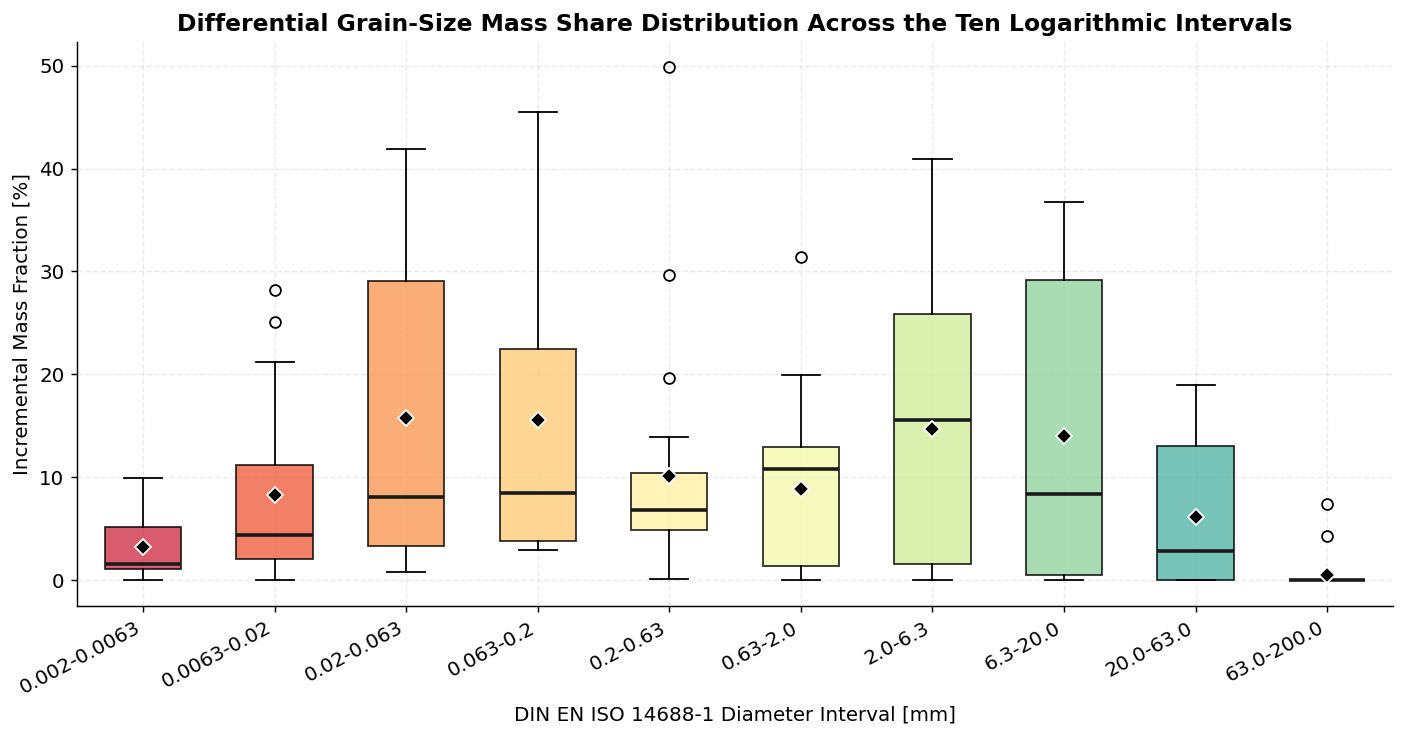

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.8))
bin_labels = [f"{DIAMETERS[i]}-{DIAMETERS[i+1]}" for i in range(10)]
bin_masses = np.diff(Y_train, axis=1)
box_colors = sns.color_palette("Spectral", n_colors=10)

bp = ax.boxplot(bin_masses, patch_artist=True, widths=0.58, showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "white", "markersize": 6})
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.82)
for median in bp["medians"]:
    median.set(color="#1a1a1a", linewidth=2)

ax.set_xticklabels(bin_labels, rotation=28, ha="right")
ax.set_xlabel("DIN EN ISO 14688-1 Diameter Interval [mm]")
ax.set_ylabel("Incremental Mass Fraction [%]")
ax.set_title("Differential Grain-Size Mass Share Distribution Across the Ten Logarithmic Intervals")
plt.tight_layout()
plt.show()

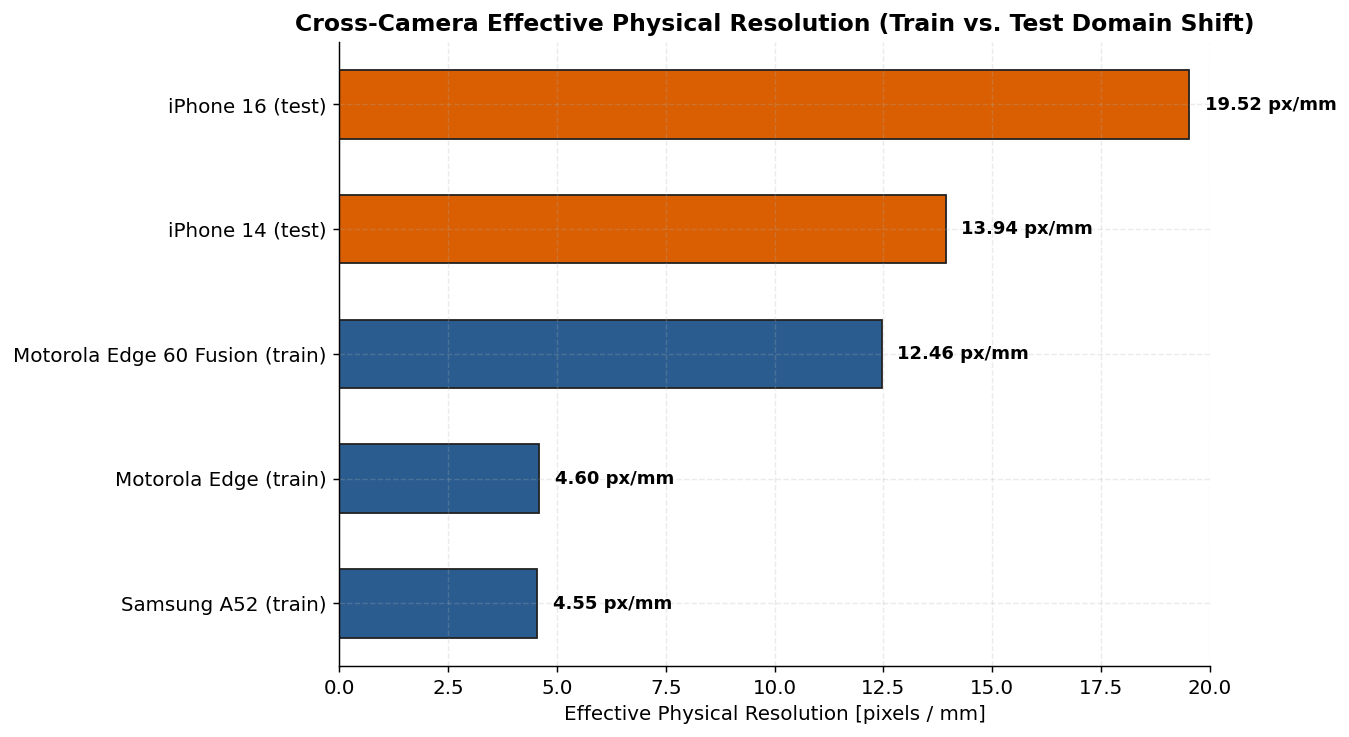

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))
cam_summary = full_manifest.groupby(["camera_model", "split"])["eff_ppm"].first().reset_index()
cam_summary = cam_summary.sort_values("eff_ppm")
bar_colors = ["#2b5c8f" if s == "train" else "#d95f02" for s in cam_summary["split"]]
bars = ax.barh(cam_summary["camera_model"] + " (" + cam_summary["split"] + ")", cam_summary["eff_ppm"], color=bar_colors, edgecolor="#222222", height=0.55)
for bar, val in zip(bars, cam_summary["eff_ppm"]):
    ax.text(val + 0.35, bar.get_y() + bar.get_height() / 2, f"{val:.2f} px/mm", va="center", fontweight="bold", fontsize=10)
ax.set_xlim(0, 20)
ax.set_xlabel("Effective Physical Resolution [pixels / mm]")
ax.set_title("Cross-Camera Effective Physical Resolution (Train vs. Test Domain Shift)")
plt.tight_layout()
plt.show()

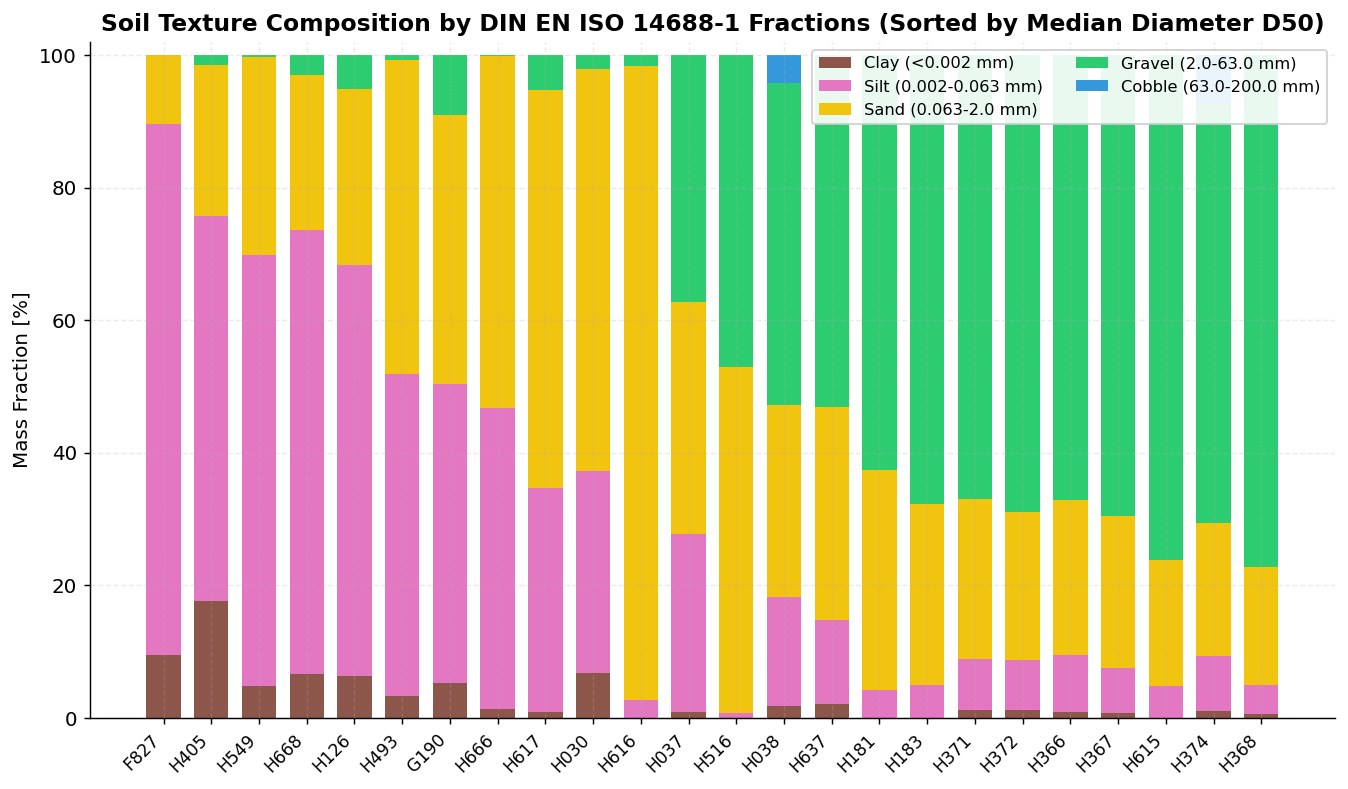

In [7]:
fig, ax = plt.subplots(figsize=(10.5, 6.2))
soil_comp = geotech_df.sort_values("D50_mm").reset_index(drop=True)
x_pos = np.arange(len(soil_comp))
ax.bar(x_pos, soil_comp["Clay_pct"], label="Clay (<0.002 mm)", color="#8c564b", width=0.72)
ax.bar(x_pos, soil_comp["Silt_pct"], bottom=soil_comp["Clay_pct"], label="Silt (0.002-0.063 mm)", color="#e377c2", width=0.72)
b2 = soil_comp["Clay_pct"] + soil_comp["Silt_pct"]
ax.bar(x_pos, soil_comp["Sand_pct"], bottom=b2, label="Sand (0.063-2.0 mm)", color="#f1c40f", width=0.72)
b3 = b2 + soil_comp["Sand_pct"]
ax.bar(x_pos, soil_comp["Gravel_pct"], bottom=b3, label="Gravel (2.0-63.0 mm)", color="#2ecc71", width=0.72)
b4 = b3 + soil_comp["Gravel_pct"]
ax.bar(x_pos, 100.0 - b4, bottom=b4, label="Cobble (63.0-200.0 mm)", color="#3498db", width=0.72)
ax.set_xticks(x_pos)
ax.set_xticklabels(soil_comp["sample_id"], rotation=45, ha="right", fontsize=9.5)
ax.set_ylim(0, 102)
ax.set_ylabel("Mass Fraction [%]")
ax.set_title("Soil Texture Composition by DIN EN ISO 14688-1 Fractions (Sorted by Median Diameter D50)")
ax.legend(loc="upper right", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

# 5. Physical-Scale Resampling and Leak-Free Sample-Level Cross-Validation

To eliminate scale-induced domain shift between training cameras ($\text{PPM}_{\text{eff}} \approx 4.56\text{--}12.47\text{ px/mm}$) and test cameras ($\text{PPM}_{\text{eff}} = 13.94\text{--}19.53\text{ px/mm}$), we resample every photograph to a **canonical fine scale** of $\text{PPM}_{\text{fine}} = 4.5\text{ px/mm}$ ($0.222\text{ mm/px}$) and a **canonical coarse scale** of $\text{PPM}_{\text{coarse}} = 1.5\text{ px/mm}$ ($0.667\text{ mm/px}$). At $4.5\text{ px/mm}$, no training image undergoes upscaling, and every $512 \times 512$ pixel crop corresponds to an exact $113.8\text{ mm} \times 113.8\text{ mm}$ physical soil patch.

For validation, we construct an **8-Fold Stratified K-Fold split at the `sample_id` level** (3 validation samples per fold), stratified by quantile bins of $\log_{10}(D_{50})$ so every fold spans fine-grained clays/silts, sands, and coarse gravels without any image-level leakage.

In [8]:
CANONICAL_PPM_FINE = 4.5
CANONICAL_PPM_COARSE = 1.5

def load_and_rescale_image(path, eff_ppm, target_ppm):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        w, h = im.size
        scale = target_ppm / eff_ppm
        new_w = max(64, int(round(w * scale)))
        new_h = max(64, int(round(h * scale)))
        resample_mode = Image.Resampling.LANCZOS if scale < 1.0 else Image.Resampling.BICUBIC
        im_res = im.resize((new_w, new_h), resample=resample_mode)
    return np.asarray(im_res, dtype=np.uint8)

def center_crop_or_pad(img, crop_size=512):
    h, w, c = img.shape
    if h < crop_size or w < crop_size:
        pad_h = max(0, crop_size - h)
        pad_w = max(0, crop_size - w)
        img = np.pad(img, ((pad_h // 2, pad_h - pad_h // 2), (pad_w // 2, pad_w - pad_w // 2), (0, 0)), mode="reflect")
        h, w, _ = img.shape
    y0 = (h - crop_size) // 2
    x0 = (w - crop_size) // 2
    return img[y0:y0 + crop_size, x0:x0 + crop_size]

N_FOLDS = 8
d50_bins = pd.qcut(np.log10(geotech_df["D50_mm"]), q=3, labels=False)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df["fold"] = -1
for fold_idx, (_, val_idx) in enumerate(skf.split(train_df, d50_bins)):
    train_df.loc[val_idx, "fold"] = fold_idx

fold_map = dict(zip(train_df["sample_id"], train_df["fold"]))
train_manifest["fold"] = train_manifest["sample_id"].map(fold_map)

print("Sample-level 8-fold assignment summary:")
print(train_df.groupby("fold").agg(
    n_samples=("sample_id", "count"),
    mean_D50=("sample_id", lambda s: geotech_df.loc[geotech_df["sample_id"].isin(s), "D50_mm"].mean())
).round(3).to_string())

Sample-level 8-fold assignment summary:
      n_samples  mean_D50
fold                     
0             3     2.048
1             3     2.082
2             3     2.060
3             3     1.655
4             3     2.478
5             3     2.147
6             3     2.452
7             3     2.059


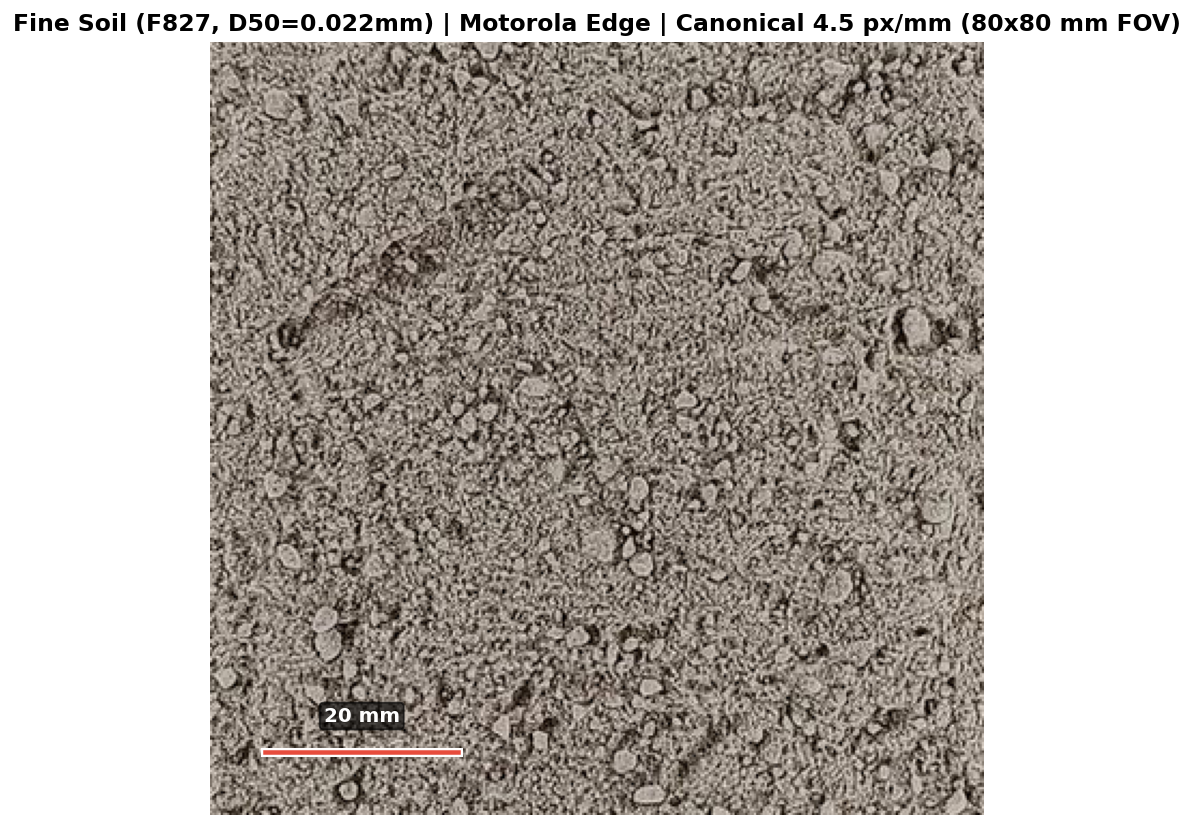

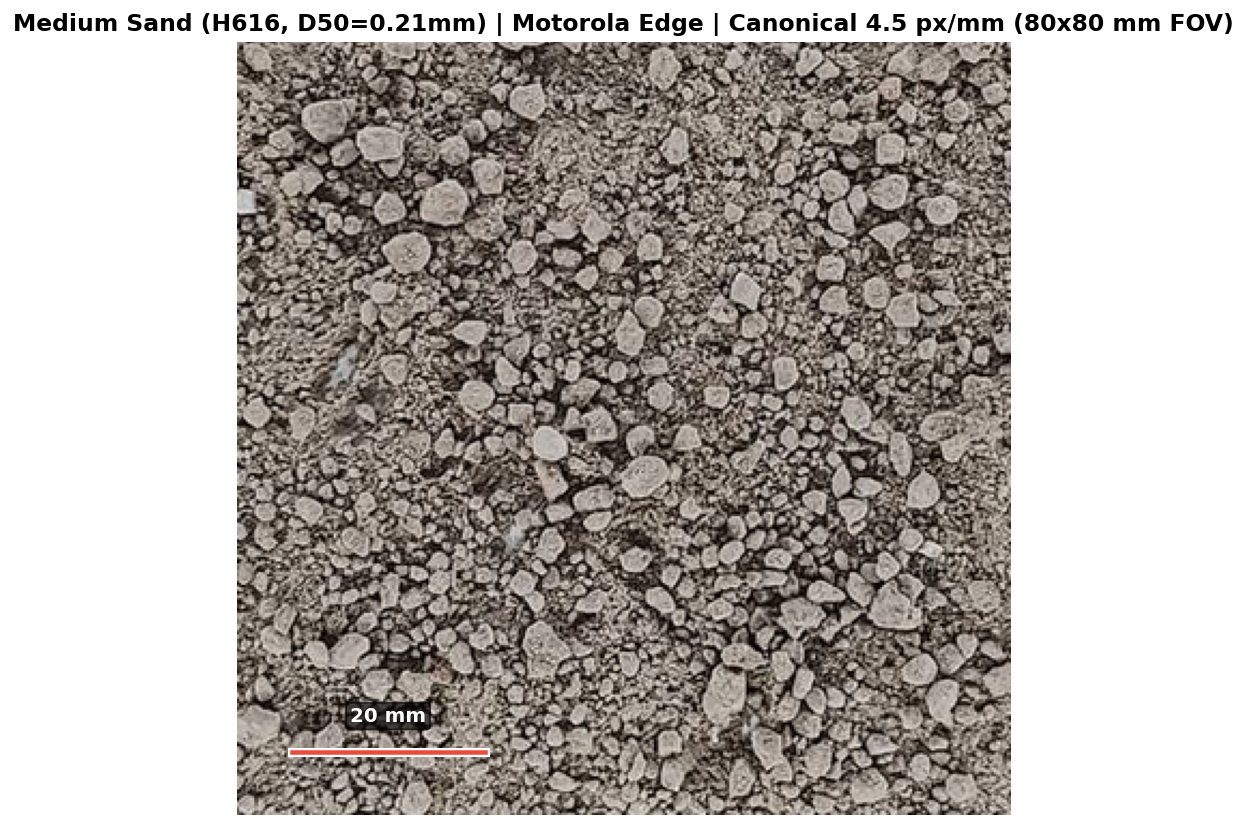

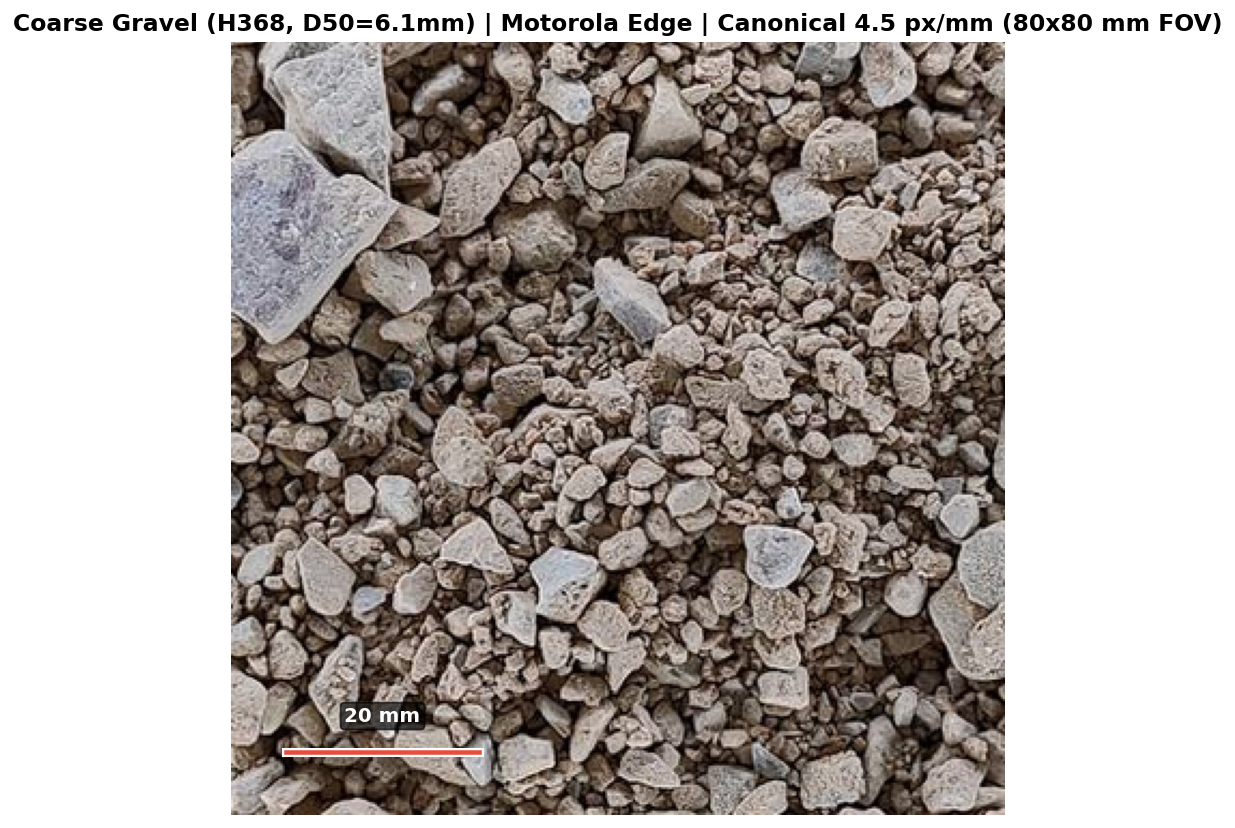

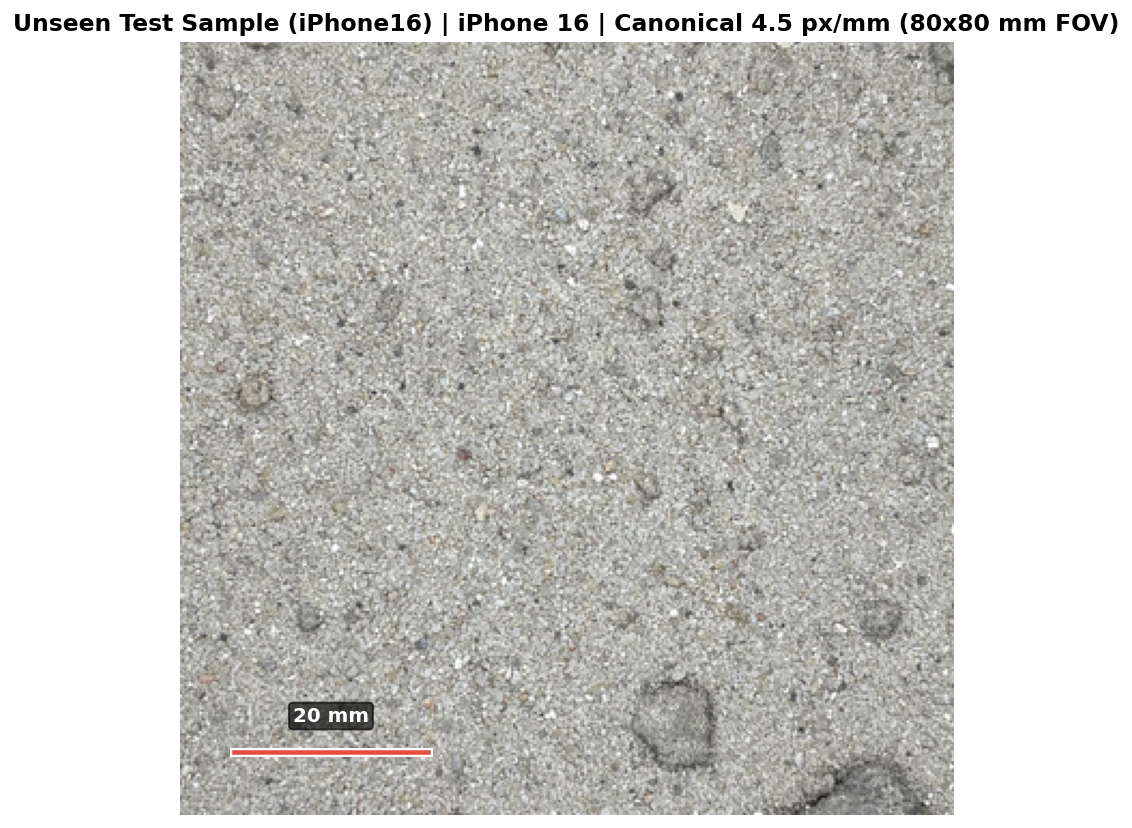

In [9]:
sample_examples = [
    ("Fine Soil (F827, D50=0.022mm)", train_manifest[train_manifest["sample_id"] == "F827"].iloc[0]),
    ("Medium Sand (H616, D50=0.21mm)", train_manifest[train_manifest["sample_id"] == "H616"].iloc[0]),
    ("Coarse Gravel (H368, D50=6.1mm)", train_manifest[train_manifest["sample_id"] == "H368"].iloc[0]),
    ("Unseen Test Sample (iPhone16)", test_manifest[test_manifest["camera_model"] == "iPhone 16"].iloc[0])
]

for title_str, row in sample_examples:
    img_fine = load_and_rescale_image(row["path"], row["eff_ppm"], CANONICAL_PPM_FINE)
    patch = center_crop_or_pad(img_fine, 360)
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.imshow(patch)
    scale_bar_px = int(round(20.0 * CANONICAL_PPM_FINE))
    ax.plot([25, 25 + scale_bar_px], [330, 330], color="white", linewidth=5)
    ax.plot([25, 25 + scale_bar_px], [330, 330], color="#e74c3c", linewidth=2.5)
    ax.text(25 + scale_bar_px / 2, 316, "20 mm", color="white", ha="center", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.65))
    ax.set_title(f"{title_str} | {row['camera_model']} | Canonical 4.5 px/mm (80x80 mm FOV)")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

# 6. Physics-Informed Granulometric and Spectral Feature Extraction

We engineer a domain-grounded feature vector for every photograph rescaled to canonical physical resolution:
1. **Mathematical Morphology Granulometry (Virtual Sieving)**: On luminance $L$, we apply grayscale morphological openings $\gamma_r(L)$ with disk structuring elements of physical radii $r \in \{0.5, 1.0, 2.0, 4.0, 8.0, 14.0\}\text{ mm}$. By Matheron's granulometric axioms, the normalized volume loss $G(r) = 1 - \frac{\sum \gamma_r(L)}{\sum L}$ acts as an optical analog of a cumulative sieve curve.
2. **2D Isotropic FFT Radial Power Spectrum**: Computing the 2D power spectrum $| \mathcal{F}(L) |^2$ and azimuthally averaging over physical wavenumber rings $k = 1/\lambda$ ($\lambda \in [0.5, 64]\text{ mm}$) yields band-power features aligned to DIN EN ISO 14688-1 sand/gravel scales, plus the log-log spectral decay slope $\beta$ (Minkowski-Bouligand fractal surface dimension proxy).
3. **Multi-Scale Edge & Laplacian Energy**: Scharr gradient magnitude and Laplacian variance at Gaussian physical scales $\sigma \in \{0.4, 1.0, 2.5, 6.0\}\text{ mm}$.
4. **GLCM & Rotation-Invariant LBP**: Second-order texture statistics (contrast, dissimilarity, homogeneity, energy, correlation) at physical pixel offsets corresponding to $0.45\text{ mm}$, $1.33\text{ mm}$, and $3.55\text{ mm}$, plus uniform LBP entropy.
5. **Illumination-Normalized Colorimetry**: CIE-$L^*a^*b^*$ and HSV quantiles capturing mineralogical and moisture cues.

In [10]:
MORPH_RADII_MM = [0.5, 1.0, 2.0, 4.0, 8.0, 14.0]
FFT_BANDS_MM = [(0.45, 0.9), (0.9, 2.0), (2.0, 4.5), (4.5, 10.0), (10.0, 25.0), (25.0, 60.0)]
EDGE_SIGMAS_MM = [0.4, 1.0, 2.5, 6.0]

def extract_physics_features_single(img_fine, img_coarse):
    patch_f = center_crop_or_pad(img_fine, 512)
    patch_c = center_crop_or_pad(img_coarse, 256)

    lab_f = cv2.cvtColor(patch_f, cv2.COLOR_RGB2LAB).astype(np.float32)
    hsv_f = cv2.cvtColor(patch_f, cv2.COLOR_RGB2HSV).astype(np.float32)
    gray_f = cv2.cvtColor(patch_f, cv2.COLOR_RGB2GRAY).astype(np.float32)
    gray_c = cv2.cvtColor(patch_c, cv2.COLOR_RGB2GRAY).astype(np.float32)

    gray_norm = (gray_f - np.mean(gray_f)) / (np.std(gray_f) + 1e-6)
    gray_u8 = np.clip((gray_norm * 40.0) + 128.0, 0, 255).astype(np.uint8)

    feats = {}

    # 1. Colorimetric & Luminance Quantiles
    for name, ch in [("L", lab_f[:, :, 0]), ("a", lab_f[:, :, 1]), ("b", lab_f[:, :, 2]), ("S", hsv_f[:, :, 1])]:
        feats[f"color_{name}_mean"] = float(np.mean(ch))
        feats[f"color_{name}_std"] = float(np.std(ch))
        feats[f"color_{name}_q10"] = float(np.percentile(ch, 10))
        feats[f"color_{name}_q50"] = float(np.percentile(ch, 50))
        feats[f"color_{name}_q90"] = float(np.percentile(ch, 90))

    # 2. Virtual Sieving via Morphological Opening Granulometry
    base_sum = float(np.sum(gray_u8)) + 1e-6
    prev_val = 0.0
    gray_small = cv2.resize(gray_u8, (256, 256), interpolation=cv2.INTER_AREA)
    base_small = float(np.sum(gray_small)) + 1e-6
    for r_mm in MORPH_RADII_MM:
        r_px = max(1, int(round(r_mm * (CANONICAL_PPM_FINE * 0.5))))
        opened = opening(gray_small, disk(r_px))
        cum_loss = 1.0 - (float(np.sum(opened)) / base_small)
        feats[f"morph_cum_{r_mm}mm"] = cum_loss
        feats[f"morph_diff_{r_mm}mm"] = cum_loss - prev_val
        prev_val = cum_loss

    # 3. 2D Isotropic FFT Radial Power Spectrum (Fine & Coarse)
    for tag, g_arr, ppm_val in [("fine", gray_norm, CANONICAL_PPM_FINE), ("coarse", (gray_c - np.mean(gray_c)) / (np.std(gray_c) + 1e-6), CANONICAL_PPM_COARSE)]:
        H, W = g_arr.shape
        win = np.outer(np.hanning(H), np.hanning(W))
        fft_mag = np.abs(np.fft.fftshift(np.fft.fft2(g_arr * win))) ** 2
        cy, cx = H // 2, W // 2
        yy, xx = np.ogrid[:H, :W]
        rr = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
        freq_per_mm = rr * (ppm_val / float(H))
        total_power = float(np.sum(fft_mag)) + 1e-8
        for l_min, l_max in FFT_BANDS_MM:
            f_min, f_max = 1.0 / l_max, 1.0 / l_min
            mask = (freq_per_mm >= f_min) & (freq_per_mm < f_max)
            band_p = float(np.sum(fft_mag[mask])) / total_power if np.any(mask) else 0.0
            feats[f"fft_{tag}_{l_min}_{l_max}mm"] = np.log1p(band_p * 1e4)

        valid = (freq_per_mm > 0.02) & (freq_per_mm < ppm_val * 0.45)
        if np.any(valid):
            slope, _, _, _, _ = stats.linregress(np.log10(freq_per_mm[valid]), np.log10(fft_mag[valid] + 1e-8))
            feats[f"fft_{tag}_spectral_slope"] = float(slope)
        else:
            feats[f"fft_{tag}_spectral_slope"] = 0.0

    # 4. Multi-Scale Edge & Laplacian Energy
    for sig_mm in EDGE_SIGMAS_MM:
        sig_px = sig_mm * CANONICAL_PPM_FINE
        blur = ndimage.gaussian_filter(gray_norm, sigma=sig_px)
        gx = cv2.Scharr(blur, cv2.CV_32F, 1, 0)
        gy = cv2.Scharr(blur, cv2.CV_32F, 0, 1)
        gmag = np.sqrt(gx ** 2 + gy ** 2)
        lap = cv2.Laplacian(blur, cv2.CV_32F)
        feats[f"edge_mean_{sig_mm}mm"] = float(np.mean(gmag))
        feats[f"edge_p90_{sig_mm}mm"] = float(np.percentile(gmag, 90))
        feats[f"lap_var_{sig_mm}mm"] = float(np.var(lap))

    # 5. GLCM & Rotation-Invariant LBP
    q_img = (gray_u8 // 16).astype(np.uint8)
    dists_px = [2, 6, 16]
    glcm = graycomatrix(q_img, distances=dists_px, angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=16, symmetric=True, normed=True)
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
        vals = graycoprops(glcm, prop)
        for d_i, d_px in enumerate(dists_px):
            feats[f"glcm_{prop}_d{d_px}"] = float(np.mean(vals[d_i]))

    for rad in [2, 4]:
        lbp = local_binary_pattern(gray_u8, P=8 * rad, R=rad, method="uniform")
        hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 8 * rad + 3), density=True)
        feats[f"lbp_r{rad}_entropy"] = float(-np.sum(hist * np.log2(hist + 1e-12)))
        feats[f"lbp_r{rad}_max"] = float(np.max(hist))

    return feats

def build_physics_table(manifest_df):
    rows = []
    for _, r in manifest_df.iterrows():
        im_f = load_and_rescale_image(r["path"], r["eff_ppm"], CANONICAL_PPM_FINE)
        im_c = load_and_rescale_image(r["path"], r["eff_ppm"], CANONICAL_PPM_COARSE)
        f = extract_physics_features_single(im_f, im_c)
        f["sample_id"] = r["sample_id"]
        f["filename"] = r["filename"]
        rows.append(f)
    return pd.DataFrame(rows)

t0 = time.time()
train_phys_img = build_physics_table(train_manifest)
test_phys_img = build_physics_table(test_manifest)
phys_cols = [c for c in train_phys_img.columns if c not in ("sample_id", "filename")]

train_phys_sample = train_phys_img.groupby("sample_id")[phys_cols].agg(["mean", "std"]).fillna(0.0)
train_phys_sample.columns = [f"{a}_{b}" for a, b in train_phys_sample.columns]
train_phys_sample = train_phys_sample.reindex(train_df["sample_id"]).reset_index()

test_phys_sample = test_phys_img.groupby("sample_id")[phys_cols].agg(["mean", "std"]).fillna(0.0)
test_phys_sample.columns = [f"{a}_{b}" for a, b in test_phys_sample.columns]
test_phys_sample = test_phys_sample.reindex(sub_df["sample_id"]).reset_index()

phys_feat_names = [c for c in train_phys_sample.columns if c != "sample_id"]
print(f"Extracted {len(phys_cols)} per-image physics features ({len(phys_feat_names)} sample-aggregated) in {time.time()-t0:.1f}s.")

Extracted 77 per-image physics features (154 sample-aggregated) in 344.3s.


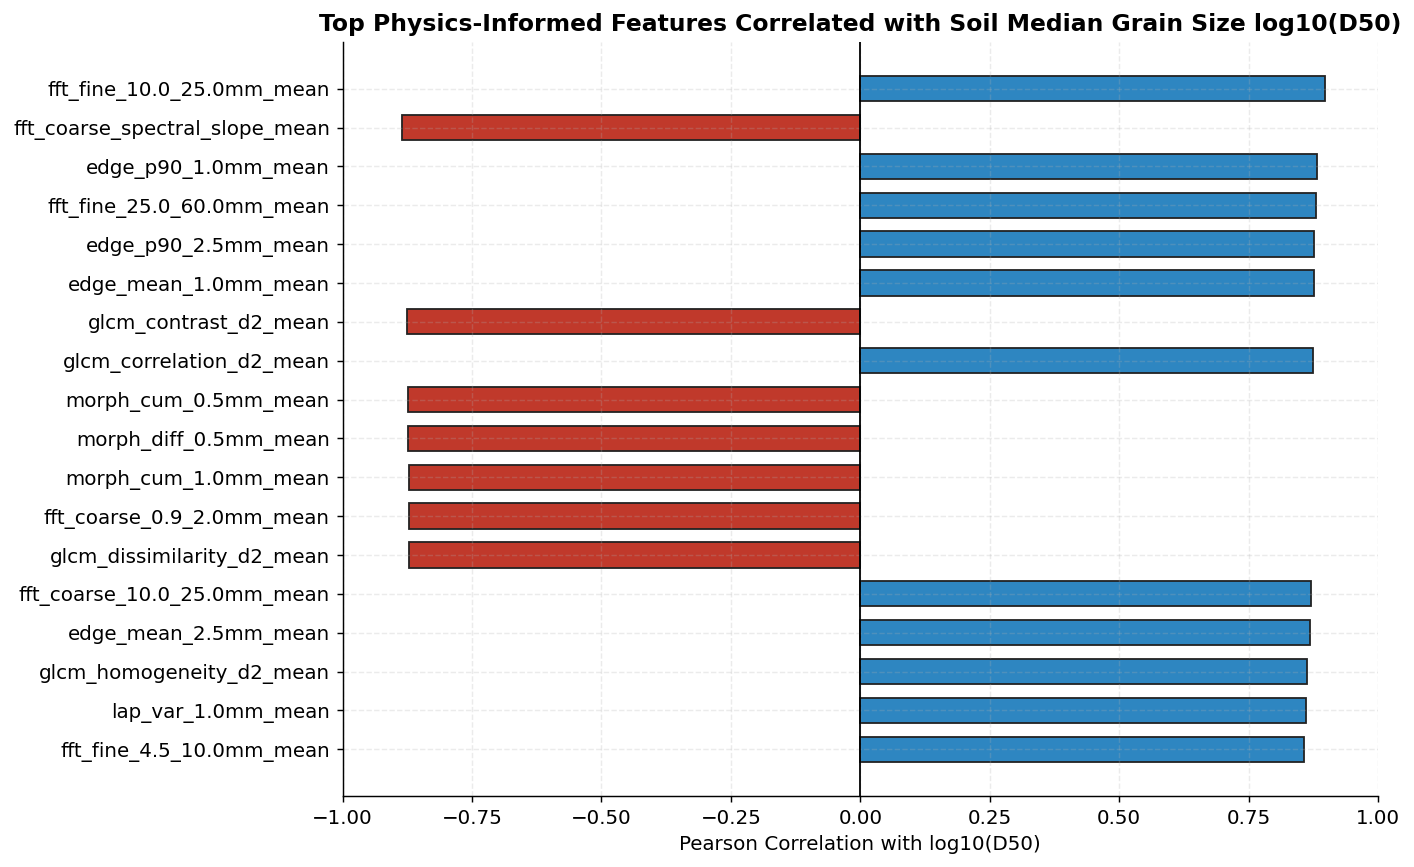

In [11]:
corrs = []
d50_vals = geotech_df.set_index("sample_id").loc[train_df["sample_id"], "D50_mm"].values
log_d50 = np.log10(d50_vals)
for col in phys_feat_names:
    v = train_phys_sample[col].values
    if np.std(v) > 1e-9:
        r_val, _ = stats.pearsonr(v, log_d50)
        corrs.append((col, r_val))
corrs.sort(key=lambda x: abs(x[1]), reverse=True)
top_corrs = corrs[:18]

fig, ax = plt.subplots(figsize=(11, 6.8))
names_c = [x[0] for x in top_corrs][::-1]
vals_c = [x[1] for x in top_corrs][::-1]
colors_c = ["#2e86c1" if v > 0 else "#c0392b" for v in vals_c]
ax.barh(names_c, vals_c, color=colors_c, edgecolor="#222222", height=0.65)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_xlim(-1.0, 1.0)
ax.set_xlabel("Pearson Correlation with log10(D50)")
ax.set_title("Top Physics-Informed Features Correlated with Soil Median Grain Size log10(D50)")
plt.tight_layout()
plt.show()

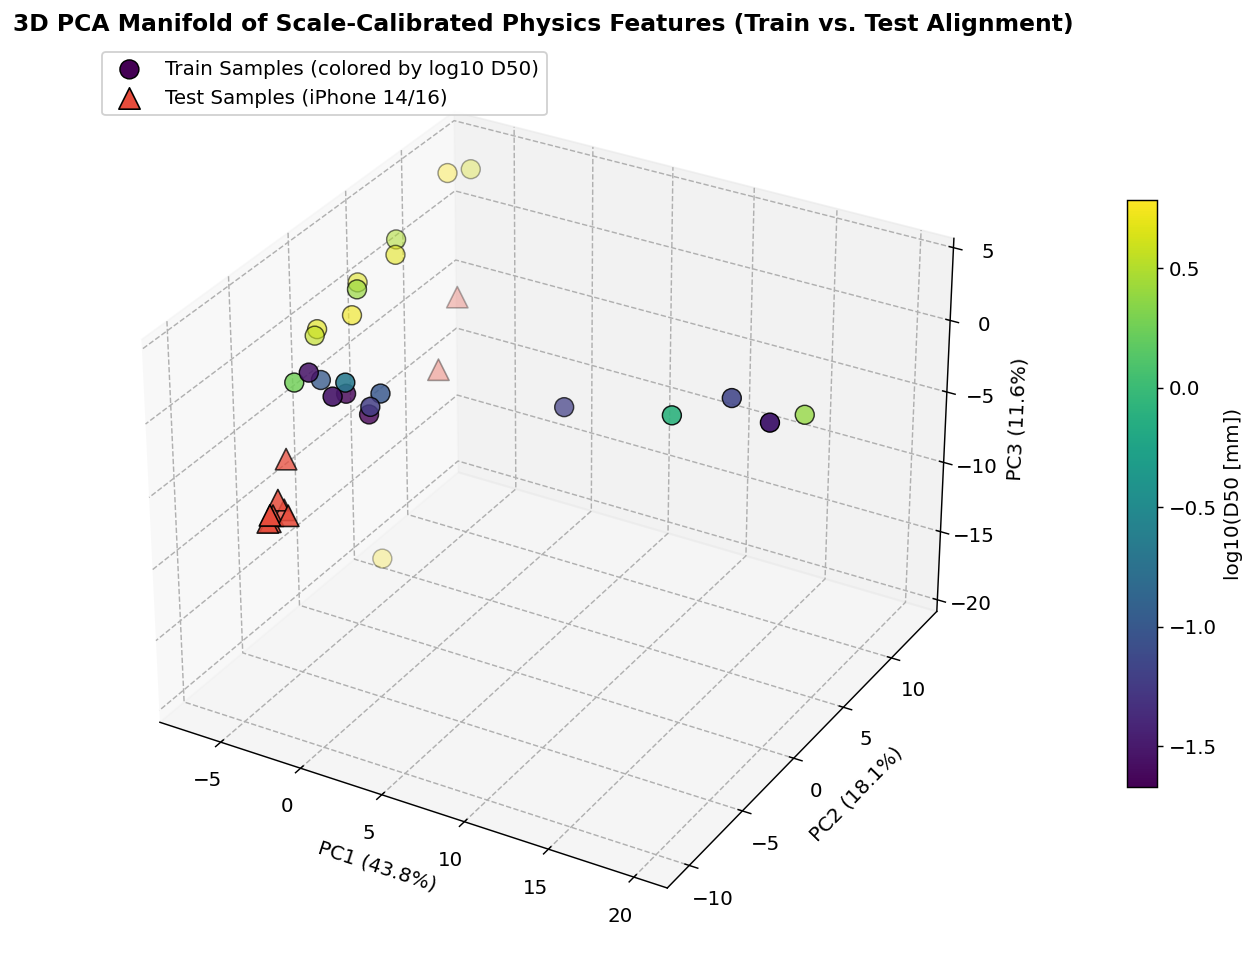

In [12]:
scaler_vis = RobustScaler()
X_vis_tr = scaler_vis.fit_transform(train_phys_sample[phys_feat_names].values)
X_vis_te = scaler_vis.transform(test_phys_sample[phys_feat_names].values)
pca_vis = PCA(n_components=3, random_state=SEED)
Z_tr = pca_vis.fit_transform(X_vis_tr)
Z_te = pca_vis.transform(X_vis_te)

fig = plt.figure(figsize=(10.5, 7.5))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(Z_tr[:, 0], Z_tr[:, 1], Z_tr[:, 2], c=log_d50, cmap="viridis", s=110, edgecolors="black", linewidth=0.8, label="Train Samples (colored by log10 D50)")
ax.scatter(Z_te[:, 0], Z_te[:, 1], Z_te[:, 2], c="#e74c3c", marker="^", s=140, edgecolors="black", linewidth=0.9, label="Test Samples (iPhone 14/16)")
cbar = fig.colorbar(sc, ax=ax, shrink=0.65, pad=0.1)
cbar.set_label("log10(D50 [mm])")
ax.set_xlabel(f"PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_zlabel(f"PC3 ({pca_vis.explained_variance_ratio_[2]*100:.1f}%)")
ax.set_title("3D PCA Manifold of Scale-Calibrated Physics Features (Train vs. Test Alignment)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 7. Model Family 1: Physics-Informed Tabular & Spectral Ensemble

We train four distinct tabular estimators on the standardized physics features under the exact 8-fold sample-level CV:
1. **Ridge Regression** ($L_2$-regularized linear model, ideal for $N=24$ high-dimensional stability).
2. **Partial Least Squares (PLS) Regression** (extracting latent granulometric components aligned with the 10-dimensional target covariance).
3. **ExtraTrees Regressor** (randomized ensemble capturing non-linear morphological interactions).
4. **LightGBM** (shallow-depth gradient boosted trees with strong $L_1/L_2$ regularization).

All raw predictions are projected onto the monotonic $[0, 100]$ cone via isotonic regression with $F_{11}=100.0$.

In [13]:
X_phys_all = train_phys_sample[phys_feat_names].values
X_phys_test = test_phys_sample[phys_feat_names].values
folds_arr = train_df["fold"].values

oof_ridge = np.zeros_like(Y_train)
oof_pls = np.zeros_like(Y_train)
oof_et = np.zeros_like(Y_train)
oof_lgb = np.zeros_like(Y_train)

pred_ridge = np.zeros((len(sub_df), 11))
pred_pls = np.zeros((len(sub_df), 11))
pred_et = np.zeros((len(sub_df), 11))
pred_lgb = np.zeros((len(sub_df), 11))

for fold in range(N_FOLDS):
    tr_idx = np.where(folds_arr != fold)[0]
    va_idx = np.where(folds_arr == fold)[0]

    scaler = RobustScaler()
    X_tr = np.clip(scaler.fit_transform(X_phys_all[tr_idx]), -5.0, 5.0)
    X_va = np.clip(scaler.transform(X_phys_all[va_idx]), -5.0, 5.0)
    X_te = np.clip(scaler.transform(X_phys_test), -5.0, 5.0)
    Y_tr = Y_train[tr_idx, :10]

    # Ridge
    m_ridge = Ridge(alpha=65.0, random_state=SEED)
    m_ridge.fit(X_tr, Y_tr)
    oof_ridge[va_idx] = project_monotonic_curve(np.hstack([m_ridge.predict(X_va), np.full((len(va_idx), 1), 100.0)]))
    pred_ridge += project_monotonic_curve(np.hstack([m_ridge.predict(X_te), np.full((len(X_te), 1), 100.0)])) / N_FOLDS

    # PLS
    m_pls = PLSRegression(n_components=min(4, len(tr_idx) - 1))
    m_pls.fit(X_tr, Y_tr)
    oof_pls[va_idx] = project_monotonic_curve(np.hstack([m_pls.predict(X_va), np.full((len(va_idx), 1), 100.0)]))
    pred_pls += project_monotonic_curve(np.hstack([m_pls.predict(X_te), np.full((len(X_te), 1), 100.0)])) / N_FOLDS

    # ExtraTrees
    m_et = ExtraTreesRegressor(n_estimators=300, max_depth=5, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
    m_et.fit(X_tr, Y_tr)
    oof_et[va_idx] = project_monotonic_curve(np.hstack([m_et.predict(X_va), np.full((len(va_idx), 1), 100.0)]))
    pred_et += project_monotonic_curve(np.hstack([m_et.predict(X_te), np.full((len(X_te), 1), 100.0)])) / N_FOLDS

    # LightGBM (target-wise L1 objective aligned with EMD)
    va_lgb = np.zeros((len(va_idx), 11))
    te_lgb = np.zeros((len(X_te), 11))
    va_lgb[:, 10] = 100.0
    te_lgb[:, 10] = 100.0
    for k in range(10):
        m_lgb = lgb.LGBMRegressor(
            objective="regression_l1",
            n_estimators=120,
            learning_rate=0.04,
            num_leaves=5,
            max_depth=3,
            min_child_samples=3,
            subsample=0.85,
            colsample_bytree=0.5,
            reg_alpha=1.0,
            reg_lambda=5.0,
            random_state=SEED + k,
            verbose=-1
        )
        m_lgb.fit(X_tr, Y_tr[:, k])
        va_lgb[:, k] = m_lgb.predict(X_va)
        te_lgb[:, k] = m_lgb.predict(X_te)
    oof_lgb[va_idx] = project_monotonic_curve(va_lgb)
    pred_lgb += project_monotonic_curve(te_lgb) / N_FOLDS

print(f"Model 1a (Physics Ridge)      OOF EMD: {compute_emd_batch(Y_train, oof_ridge):.4f}")
print(f"Model 1b (Physics PLS)        OOF EMD: {compute_emd_batch(Y_train, oof_pls):.4f}")
print(f"Model 1c (Physics ExtraTrees) OOF EMD: {compute_emd_batch(Y_train, oof_et):.4f}")
print(f"Model 1d (Physics LightGBM)   OOF EMD: {compute_emd_batch(Y_train, oof_lgb):.4f}")

Model 1a (Physics Ridge)      OOF EMD: 41.1952
Model 1b (Physics PLS)        OOF EMD: 37.4001
Model 1c (Physics ExtraTrees) OOF EMD: 45.1200
Model 1d (Physics LightGBM)   OOF EMD: 45.4595


# 8. Model Family 2: Multi-Scale Foundation Vision Backbones with Attention-MIL and Exact EMD Loss

We leverage two complementary pretrained vision backbones via `timm` on GPU:
1. **`convnext_small.fb_in22k_ft_in1k_384`**: Hierarchical convolutional architecture sensitive to multi-scale local grain boundaries and texture.
2. **`vit_base_patch14_dinov2.lvd142m`**: Self-supervised Vision Transformer pretrained on LVD-142M, capturing fine-grained geometric structure without ImageNet class bias.

For each photograph, we extract multi-crop embeddings at canonical physical resolutions ($4.5\text{ px/mm}$ center + 4 quadrant crops, plus $1.5\text{ px/mm}$ macro crop), averaging across 4 rotation-invariant orientations ($0^\circ, 90^\circ, 180^\circ, 270^\circ$) to enforce $C_4$ rotational equivariance.

Because each soil sample $s$ has $M_s \in \{3, \dots, 8\}$ photographs, we aggregate the bag of photo embeddings $\{\mathbf{e}_{s,1}, \dots, \mathbf{e}_{s,M_s}\}$ using a **Gated Attention Multiple Instance Learning (MIL)** network:
$$a_{s,j} = \frac{\exp(\mathbf{w}^\top (\tanh(\mathbf{V}\mathbf{e}_{s,j}) \odot \sigma(\mathbf{U}\mathbf{e}_{s,j})))}{\sum_{m=1}^{M_s} \exp(\mathbf{w}^\top (\tanh(\mathbf{V}\mathbf{e}_{s,m}) \odot \sigma(\mathbf{U}\mathbf{e}_{s,m})))}, \qquad \mathbf{h}_s = \sum_{j=1}^{M_s} a_{s,j} \mathbf{e}_{s,j}$$

The head outputs 11 logits transformed via Softmax $\times 100$ and cumulative summation, trained directly with the **differentiable EMD loss**.

In [14]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def prepare_tensor(rgb_np, target_size):
    img = cv2.resize(rgb_np, (target_size, target_size), interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0
    img = (img - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(img.transpose(2, 0, 1))

def get_multiscale_crops(img_fine, img_coarse, target_size):
    p_f = center_crop_or_pad(img_fine, 512)
    p_c = center_crop_or_pad(img_coarse, 256)
    crops = [
        p_f[64:448, 64:448],
        p_f[0:256, 0:256],
        p_f[0:256, 256:512],
        p_f[256:512, 0:256],
        p_f[256:512, 256:512],
        p_c
    ]
    tensors = []
    for c in crops:
        tensors.append(prepare_tensor(c, target_size))
        tensors.append(prepare_tensor(np.rot90(c, 1), target_size))
    return torch.stack(tensors, dim=0)

@torch.no_grad()
def extract_backbone_embeddings(manifest_df, model_name, img_size):
    model = timm.create_model(model_name, pretrained=True, num_classes=0).to(DEVICE)
    model.eval()
    emb_dict = {}
    for _, row in manifest_df.iterrows():
        im_f = load_and_rescale_image(row["path"], row["eff_ppm"], CANONICAL_PPM_FINE)
        im_c = load_and_rescale_image(row["path"], row["eff_ppm"], CANONICAL_PPM_COARSE)
        batch = get_multiscale_crops(im_f, im_c, img_size).to(DEVICE)
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            feats = model(batch)
        feats = F.normalize(feats.float(), dim=-1)
        mean_feat = feats.mean(dim=0).cpu().numpy()
        emb_dict.setdefault(row["sample_id"], []).append(mean_feat)
    del model
    torch.cuda.empty_cache()
    gc.collect()
    return {k: np.stack(v, axis=0) for k, v in emb_dict.items()}

t0 = time.time()
print("Extracting ConvNeXt-Small embeddings...")
tr_emb_cnx = extract_backbone_embeddings(train_manifest, "convnext_small.fb_in22k_ft_in1k_384", 384)
te_emb_cnx = extract_backbone_embeddings(test_manifest, "convnext_small.fb_in22k_ft_in1k_384", 384)
print(f"ConvNeXt-Small done in {time.time()-t0:.1f}s.")

t0 = time.time()
print("Extracting DINOv2-Base embeddings...")
tr_emb_dino = extract_backbone_embeddings(train_manifest, "vit_base_patch14_dinov2.lvd142m", 518)
te_emb_dino = extract_backbone_embeddings(test_manifest, "vit_base_patch14_dinov2.lvd142m", 518)
print(f"DINOv2-Base done in {time.time()-t0:.1f}s.")

Extracting ConvNeXt-Small embeddings...


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

ConvNeXt-Small done in 92.7s.
Extracting DINOv2-Base embeddings...


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

DINOv2-Base done in 113.5s.


In [15]:
INTERVAL_WEIGHTS_T = torch.tensor(INTERVAL_WEIGHTS, dtype=torch.float32, device=DEVICE)

class DifferentiableEMDLoss(nn.Module):
    def __init__(self, weights_tensor):
        super().__init__()
        self.w = weights_tensor

    def forward(self, pred_cum, target_cum):
        diff = torch.abs(pred_cum[:, :10] - target_cum[:, :10])
        return torch.mean(torch.sum(diff * self.w.unsqueeze(0), dim=1))

class AttentionMILHead(nn.Module):
    def __init__(self, in_dim, hidden_dim=192, dropout=0.35):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.attn_v = nn.Linear(hidden_dim, hidden_dim // 2)
        self.attn_u = nn.Linear(hidden_dim, hidden_dim // 2)
        self.attn_w = nn.Linear(hidden_dim // 2, 1)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(hidden_dim // 2, 11)
        )

    def forward(self, bag_tensor):
        h = self.proj(bag_tensor)
        a = torch.tanh(self.attn_v(h)) * torch.sigmoid(self.attn_u(h))
        weights = torch.softmax(self.attn_w(a), dim=0)
        pooled = torch.sum(weights * h, dim=0, keepdim=True)
        logits = self.head(pooled)
        pmf = torch.softmax(logits, dim=-1) * 100.0
        cum = torch.cumsum(pmf, dim=-1)
        return cum

def train_mil_cv(tr_bags, te_bags, epochs=180, lr=1.5e-3):
    seed_everything(SEED)
    in_dim = next(iter(tr_bags.values())).shape[1]
    oof_preds = np.zeros_like(Y_train)
    test_preds = np.zeros((len(sub_df), 11))
    fold_histories = []
    criterion = DifferentiableEMDLoss(INTERVAL_WEIGHTS_T)

    sids_tr = train_df["sample_id"].tolist()
    sids_te = sub_df["sample_id"].tolist()

    for fold in range(N_FOLDS):
        tr_idx = np.where(folds_arr != fold)[0]
        va_idx = np.where(folds_arr == fold)[0]

        model = AttentionMILHead(in_dim=in_dim).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=2e-2)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

        best_val = 1e9
        best_state = None
        tr_hist, va_hist = [], []

        for ep in range(epochs):
            model.train()
            ep_loss = 0.0
            perm = np.random.permutation(tr_idx)
            optimizer.zero_grad()
            for i in perm:
                bag = torch.tensor(tr_bags[sids_tr[i]], dtype=torch.float32, device=DEVICE)
                bag = bag + 0.01 * torch.randn_like(bag)
                tgt = torch.tensor(Y_train[i:i+1], dtype=torch.float32, device=DEVICE)
                pred = model(bag)
                loss = criterion(pred, tgt) / len(perm)
                loss.backward()
                ep_loss += loss.item() * len(perm)
            optimizer.step()
            scheduler.step()
            tr_hist.append(ep_loss / len(perm))

            model.eval()
            with torch.no_grad():
                va_preds_list = []
                for i in va_idx:
                    bag = torch.tensor(tr_bags[sids_tr[i]], dtype=torch.float32, device=DEVICE)
                    va_preds_list.append(model(bag).cpu().numpy()[0])
                va_preds_arr = np.stack(va_preds_list, axis=0)
                va_emd = compute_emd_batch(Y_train[va_idx], va_preds_arr)
                va_hist.append(va_emd)
                if va_emd < best_val:
                    best_val = va_emd
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        fold_histories.append((tr_hist, va_hist))
        model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
        model.eval()
        with torch.no_grad():
            for i in va_idx:
                bag = torch.tensor(tr_bags[sids_tr[i]], dtype=torch.float32, device=DEVICE)
                oof_preds[i] = project_monotonic_curve(model(bag).cpu().numpy()[0])
            for j, sid in enumerate(sids_te):
                bag = torch.tensor(te_bags[sid], dtype=torch.float32, device=DEVICE)
                test_preds[j] += project_monotonic_curve(model(bag).cpu().numpy()[0]) / N_FOLDS

    return oof_preds, test_preds, fold_histories

oof_mil_cnx, pred_mil_cnx, hist_cnx = train_mil_cv(tr_emb_cnx, te_emb_cnx)
oof_mil_dino, pred_mil_dino, hist_dino = train_mil_cv(tr_emb_dino, te_emb_dino)

tr_emb_fused = {k: np.concatenate([tr_emb_cnx[k], tr_emb_dino[k]], axis=1) for k in tr_emb_cnx}
te_emb_fused = {k: np.concatenate([te_emb_cnx[k], te_emb_dino[k]], axis=1) for k in te_emb_cnx}
oof_mil_fused, pred_mil_fused, hist_fused = train_mil_cv(tr_emb_fused, te_emb_fused)

print(f"Model 2a (ConvNeXt-Small Attention-MIL) OOF EMD: {compute_emd_batch(Y_train, oof_mil_cnx):.4f}")
print(f"Model 2b (DINOv2-Base Attention-MIL)    OOF EMD: {compute_emd_batch(Y_train, oof_mil_dino):.4f}")
print(f"Model 2c (Fused Dual-Backbone MIL)      OOF EMD: {compute_emd_batch(Y_train, oof_mil_fused):.4f}")

Model 2a (ConvNeXt-Small Attention-MIL) OOF EMD: 31.6440
Model 2b (DINOv2-Base Attention-MIL)    OOF EMD: 28.4475
Model 2c (Fused Dual-Backbone MIL)      OOF EMD: 31.2343


# 9. Model Family 3: End-to-End Domain-Invariant Fine-Tuned ConvNeXt-Tiny

To complement frozen foundation representations, we fine-tune `convnext_tiny.fb_in22k_ft_in1k` end-to-end on canonical $4.5\text{ px/mm}$ patches ($384 \times 384$) using **physical-invariant geometric and ISP-shift augmentations**:
- Random $90^\circ$ rotations and horizontal/vertical flips (exact granulometric invariance).
- Photometric brightness, contrast, and channel-wise color-temperature jitter (simulating smartphone ISP differences between Motorola/Samsung and iPhone sensors).
- Exact differentiable EMD loss with cosine annealing and 4-orientation Test-Time Augmentation (TTA) aggregated across all photographs of each sample.

In [16]:
def augment_soil_patch(rgb):
    k = np.random.randint(0, 4)
    rgb = np.rot90(rgb, k).copy()
    if np.random.rand() < 0.5:
        rgb = np.fliplr(rgb).copy()
    if np.random.rand() < 0.5:
        rgb = np.flipud(rgb).copy()
    # Mild ISP color-temperature and exposure jitter
    alpha = np.random.uniform(0.88, 1.12)
    beta = np.random.uniform(-12.0, 12.0)
    ch_gains = np.random.uniform(0.94, 1.06, size=(1, 1, 3)).astype(np.float32)
    out = rgb.astype(np.float32) * alpha * ch_gains + beta
    return np.clip(out, 0, 255).astype(np.uint8)

class SoilPatchDataset(Dataset):
    def __init__(self, manifest_sub, targets_map=None, is_train=True, img_size=384):
        self.rows = manifest_sub.reset_index(drop=True)
        self.targets_map = targets_map
        self.is_train = is_train
        self.img_size = img_size
        self.cached_imgs = []
        for _, r in self.rows.iterrows():
            im_f = load_and_rescale_image(r["path"], r["eff_ppm"], CANONICAL_PPM_FINE)
            self.cached_imgs.append(center_crop_or_pad(im_f, 448))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        img = self.cached_imgs[idx]
        if self.is_train:
            h, w, _ = img.shape
            y0 = np.random.randint(0, max(1, h - 384))
            x0 = np.random.randint(0, max(1, w - 384))
            patch = img[y0:y0 + 384, x0:x0 + 384]
            patch = augment_soil_patch(patch)
            tensor = prepare_tensor(patch, self.img_size)
        else:
            patch = center_crop_or_pad(img, 384)
            tensor = torch.stack([prepare_tensor(np.rot90(patch, k), self.img_size) for k in range(4)], dim=0)

        sid = self.rows.loc[idx, "sample_id"]
        if self.targets_map is not None:
            tgt = torch.tensor(self.targets_map[sid], dtype=torch.float32)
            return tensor, tgt, sid
        return tensor, sid

class MonotonicConvNeXt(nn.Module):
    def __init__(self, backbone_name="convnext_tiny.fb_in22k_ft_in1k"):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=True, num_classes=0, drop_path_rate=0.15)
        dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Dropout(0.3),
            nn.Linear(dim, 128),
            nn.GELU(),
            nn.Linear(128, 11)
        )

    def forward(self, x):
        feat = self.backbone(x)
        logits = self.head(feat)
        pmf = torch.softmax(logits, dim=-1) * 100.0
        return torch.cumsum(pmf, dim=-1)

def run_e2e_convnext_cv(epochs=24, batch_size=16, lr=2e-4):
    seed_everything(SEED)
    targets_map = {row["sample_id"]: row[TARGET_COLS].values.astype(np.float32) for _, row in train_df.iterrows()}
    criterion = DifferentiableEMDLoss(INTERVAL_WEIGHTS_T)

    oof_e2e = np.zeros_like(Y_train)
    pred_e2e = np.zeros((len(sub_df), 11))
    sids_tr = train_df["sample_id"].tolist()
    sids_te = sub_df["sample_id"].tolist()

    te_ds = SoilPatchDataset(test_manifest, targets_map=None, is_train=False)
    te_loader = DataLoader(te_ds, batch_size=8, shuffle=False, num_workers=0)

    for fold in range(N_FOLDS):
        tr_sub = train_manifest[train_manifest["fold"] != fold]
        va_sub = train_manifest[train_manifest["fold"] == fold]

        tr_ds = SoilPatchDataset(tr_sub, targets_map=targets_map, is_train=True)
        va_ds = SoilPatchDataset(va_sub, targets_map=targets_map, is_train=False)
        tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True, num_workers=0)
        va_loader = DataLoader(va_ds, batch_size=8, shuffle=False, num_workers=0)

        model = MonotonicConvNeXt().to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
        scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

        best_val = 1e9
        best_state = None

        for ep in range(epochs):
            model.train()
            for x, y, _ in tr_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad()
                with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
                    pred = model(x)
                    loss = criterion(pred, y)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            scheduler.step()

            model.eval()
            va_bag = {}
            with torch.no_grad():
                for x_tta, _, sids in va_loader:
                    b, tta_n, c, h, w = x_tta.shape
                    x_flat = x_tta.view(b * tta_n, c, h, w).to(DEVICE)
                    with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
                        p_flat = model(x_flat).view(b, tta_n, 11).mean(dim=1).cpu().numpy()
                    for sid_i, p_i in zip(sids, p_flat):
                        va_bag.setdefault(sid_i, []).append(p_i)
            va_sample_preds = np.stack([np.mean(va_bag[s], axis=0) for s in va_sub["sample_id"].unique()], axis=0)
            va_sample_true = np.stack([targets_map[s] for s in va_sub["sample_id"].unique()], axis=0)
            val_emd = compute_emd_batch(va_sample_true, va_sample_preds)
            if val_emd < best_val:
                best_val = val_emd
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
        model.eval()
        va_bag = {}
        with torch.no_grad():
            for x_tta, _, sids in va_loader:
                b, tta_n, c, h, w = x_tta.shape
                p_flat = model(x_tta.view(b * tta_n, c, h, w).to(DEVICE)).view(b, tta_n, 11).mean(dim=1).cpu().numpy()
                for sid_i, p_i in zip(sids, p_flat):
                    va_bag.setdefault(sid_i, []).append(p_i)
        for s in va_sub["sample_id"].unique():
            idx_tr = sids_tr.index(s)
            oof_e2e[idx_tr] = project_monotonic_curve(np.mean(va_bag[s], axis=0))

        te_bag = {}
        with torch.no_grad():
            for x_tta, sids in te_loader:
                b, tta_n, c, h, w = x_tta.shape
                p_flat = model(x_tta.view(b * tta_n, c, h, w).to(DEVICE)).view(b, tta_n, 11).mean(dim=1).cpu().numpy()
                for sid_i, p_i in zip(sids, p_flat):
                    te_bag.setdefault(sid_i, []).append(p_i)
        for j, s in enumerate(sids_te):
            pred_e2e[j] += project_monotonic_curve(np.mean(te_bag[s], axis=0)) / N_FOLDS

        del model
        torch.cuda.empty_cache()
        gc.collect()

    return oof_e2e, pred_e2e

t0 = time.time()
oof_e2e_cnx, pred_e2e_cnx = run_e2e_convnext_cv()
print(f"Model 3 (End-to-End Fine-Tuned ConvNeXt-Tiny + TTA) OOF EMD: {compute_emd_batch(Y_train, oof_e2e_cnx):.4f} ({time.time()-t0:.1f}s)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Model 3 (End-to-End Fine-Tuned ConvNeXt-Tiny + TTA) OOF EMD: 31.8760 (680.3s)


# 10. Metric-Optimal Simplex Ensemble and Monotonic Post-Processing

Given $M = 8$ diverse out-of-fold predictors $\{\hat{F}^{(1)}, \dots, \hat{F}^{(8)}\}$ spanning physics-based tabular estimators, multi-scale frozen vision MIL models, and end-to-end fine-tuned CNNs, we solve the constrained convex optimization problem directly on the competition EMD objective:
$$\min_{\mathbf{w} \in \Delta^{M-1}} \frac{1}{N} \sum_{n=1}^{N} \sum_{i=1}^{10} \left| F_{n,i} - \sum_{m=1}^{M} w_m \hat{F}^{(m)}_{n,i} \right| \cdot \Delta_i \quad \text{s.t.} \quad w_m \ge 0, \; \sum_{m=1}^{M} w_m = 1$$

To guard against overfitting the ensemble weights on $N=24$ samples, we evaluate **out-of-fold nested weight optimization** (fitting $\mathbf{w}^{(-f)}$ on 7 folds and evaluating on the held-out fold $f$) before fitting the final global simplex weights.

In [17]:
model_names = [
    "Physics Ridge",
    "Physics PLS",
    "Physics ExtraTrees",
    "Physics LightGBM",
    "MIL ConvNeXt-Small",
    "MIL DINOv2-Base",
    "MIL Dual-Backbone",
    "E2E ConvNeXt-Tiny"
]
oof_list = [oof_ridge, oof_pls, oof_et, oof_lgb, oof_mil_cnx, oof_mil_dino, oof_mil_fused, oof_e2e_cnx]
pred_list = [pred_ridge, pred_pls, pred_et, pred_lgb, pred_mil_cnx, pred_mil_dino, pred_mil_fused, pred_e2e_cnx]

def optimize_simplex_weights(oof_stack, y_true):
    M = len(oof_stack)
    def obj(w):
        w = w / np.sum(w)
        blend = np.tensordot(w, oof_stack, axes=(0, 0))
        return compute_emd_batch(y_true, blend)
    init_w = np.ones(M) / M
    bounds = [(0.0, 1.0)] * M
    cons = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
    res = optimize.minimize(obj, init_w, method="SLSQP", bounds=bounds, constraints=cons, options={"maxiter": 500, "ftol": 1e-9})
    w_opt = np.maximum(0.0, res.x)
    return w_opt / np.sum(w_opt)

oof_stack = np.stack(oof_list, axis=0)
pred_stack = np.stack(pred_list, axis=0)

nested_oof = np.zeros_like(Y_train)
nested_weights = []
for fold in range(N_FOLDS):
    tr_idx = np.where(folds_arr != fold)[0]
    va_idx = np.where(folds_arr == fold)[0]
    w_f = optimize_simplex_weights(oof_stack[:, tr_idx, :], Y_train[tr_idx])
    nested_weights.append(w_f)
    nested_oof[va_idx] = project_monotonic_curve(np.tensordot(w_f, oof_stack[:, va_idx, :], axes=(0, 0)))

global_weights = optimize_simplex_weights(oof_stack, Y_train)
final_test_preds = project_monotonic_curve(np.tensordot(global_weights, pred_stack, axes=(0, 0)))

print("Individual and Ensemble OOF EMD Scores:")
for name, oof_m in zip(model_names, oof_list):
    print(f"  {name:<24s}: {compute_emd_batch(Y_train, oof_m):.4f}")
print(f"  {'Nested-CV Ensemble':<24s}: {compute_emd_batch(Y_train, nested_oof):.4f}")
print("\nOptimal Global Ensemble Weights:")
for name, w in zip(model_names, global_weights):
    print(f"  {name:<24s}: {w:.4f}")

Individual and Ensemble OOF EMD Scores:
  Physics Ridge           : 41.1952
  Physics PLS             : 37.4001
  Physics ExtraTrees      : 45.1200
  Physics LightGBM        : 45.4595
  MIL ConvNeXt-Small      : 31.6440
  MIL DINOv2-Base         : 28.4475
  MIL Dual-Backbone       : 31.2343
  E2E ConvNeXt-Tiny       : 31.8760
  Nested-CV Ensemble      : 29.6073

Optimal Global Ensemble Weights:
  Physics Ridge           : 0.0000
  Physics PLS             : 0.0478
  Physics ExtraTrees      : 0.0000
  Physics LightGBM        : 0.0000
  MIL ConvNeXt-Small      : 0.1195
  MIL DINOv2-Base         : 0.8327
  MIL Dual-Backbone       : 0.0000
  E2E ConvNeXt-Tiny       : 0.0000


# 11. Model Diagnostics, Error Decomposition, and Test Predictions

We inspect:
1. Out-of-fold EMD comparison across all individual models and the nested-CV ensemble.
2. Attention-MIL training and validation convergence curves.
3. Interval-wise Wasserstein-1 error contributions across the ten DIN EN ISO 14688-1 grain size bins.
4. Representative out-of-fold predicted vs. laboratory ground-truth cumulative curves.
5. Predicted cumulative grading curves for all 10 unseen test samples.

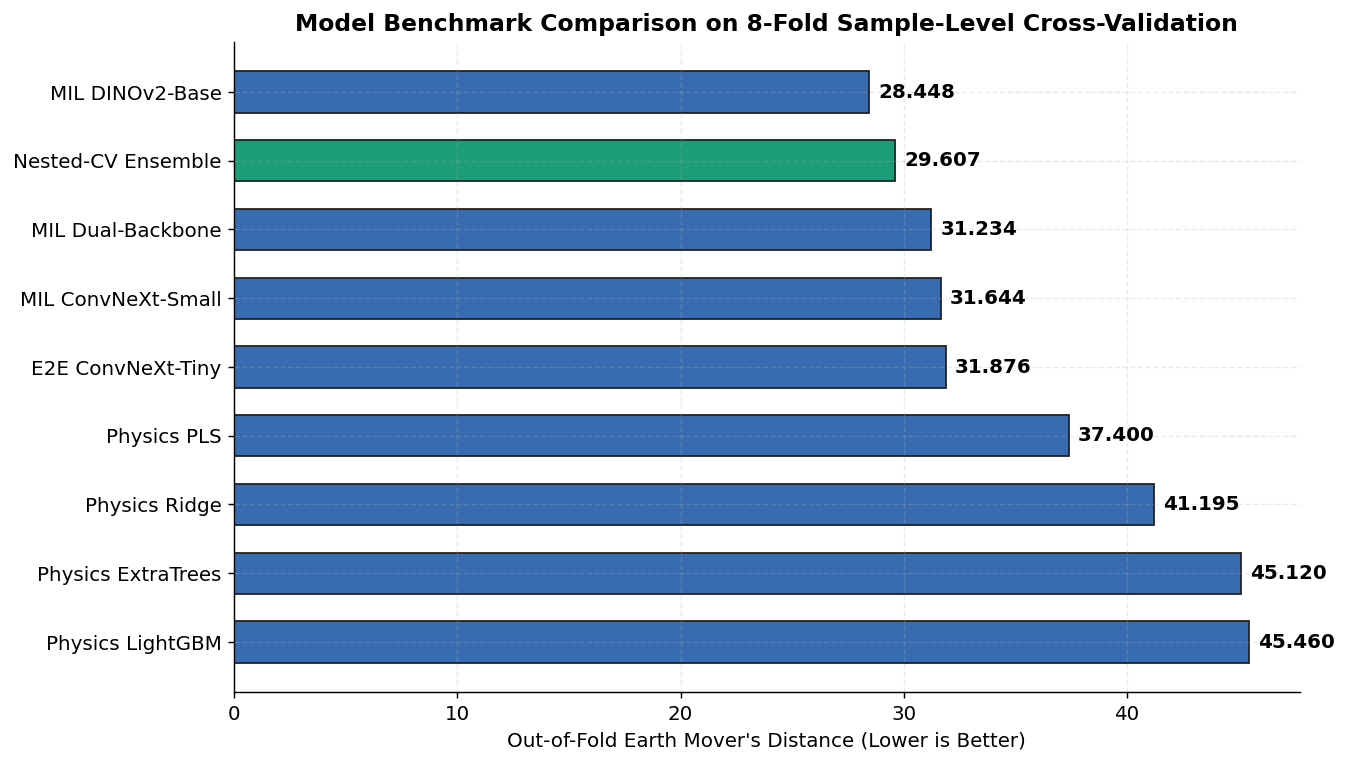

In [18]:
scores_summary = [compute_emd_batch(Y_train, m) for m in oof_list] + [compute_emd_batch(Y_train, nested_oof)]
labels_summary = model_names + ["Nested-CV Ensemble"]
order_s = np.argsort(scores_summary)[::-1]

fig, ax = plt.subplots(figsize=(10.5, 6.0))
bar_cols = ["#1b9e77" if labels_summary[i] == "Nested-CV Ensemble" else "#386cb0" for i in order_s]
bars = ax.barh([labels_summary[i] for i in order_s], [scores_summary[i] for i in order_s], color=bar_cols, edgecolor="#222222", height=0.6)
for bar, val in zip(bars, [scores_summary[i] for i in order_s]):
    ax.text(val + 0.4, bar.get_y() + bar.get_height() / 2, f"{val:.3f}", va="center", fontweight="bold")
ax.set_xlabel("Out-of-Fold Earth Mover's Distance (Lower is Better)")
ax.set_title("Model Benchmark Comparison on 8-Fold Sample-Level Cross-Validation")
ax.set_xlim(0, max(scores_summary) * 1.05)
plt.tight_layout()
plt.show()

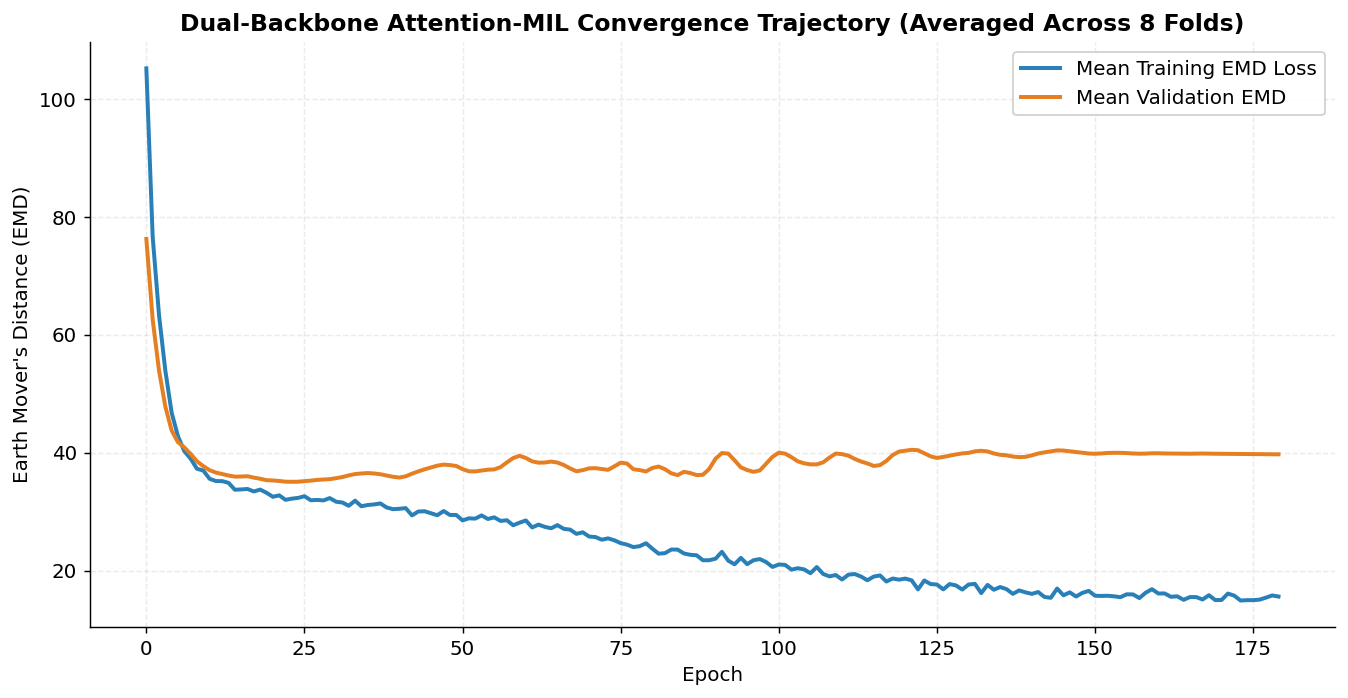

In [19]:
mean_tr_curve = np.mean([h[0] for h in hist_fused], axis=0)
mean_va_curve = np.mean([h[1] for h in hist_fused], axis=0)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.plot(mean_tr_curve, color="#2980b9", linewidth=2.2, label="Mean Training EMD Loss")
ax.plot(mean_va_curve, color="#e67e22", linewidth=2.2, label="Mean Validation EMD")
ax.set_xlabel("Epoch")
ax.set_ylabel("Earth Mover's Distance (EMD)")
ax.set_title("Dual-Backbone Attention-MIL Convergence Trajectory (Averaged Across 8 Folds)")
ax.legend()
plt.tight_layout()
plt.show()

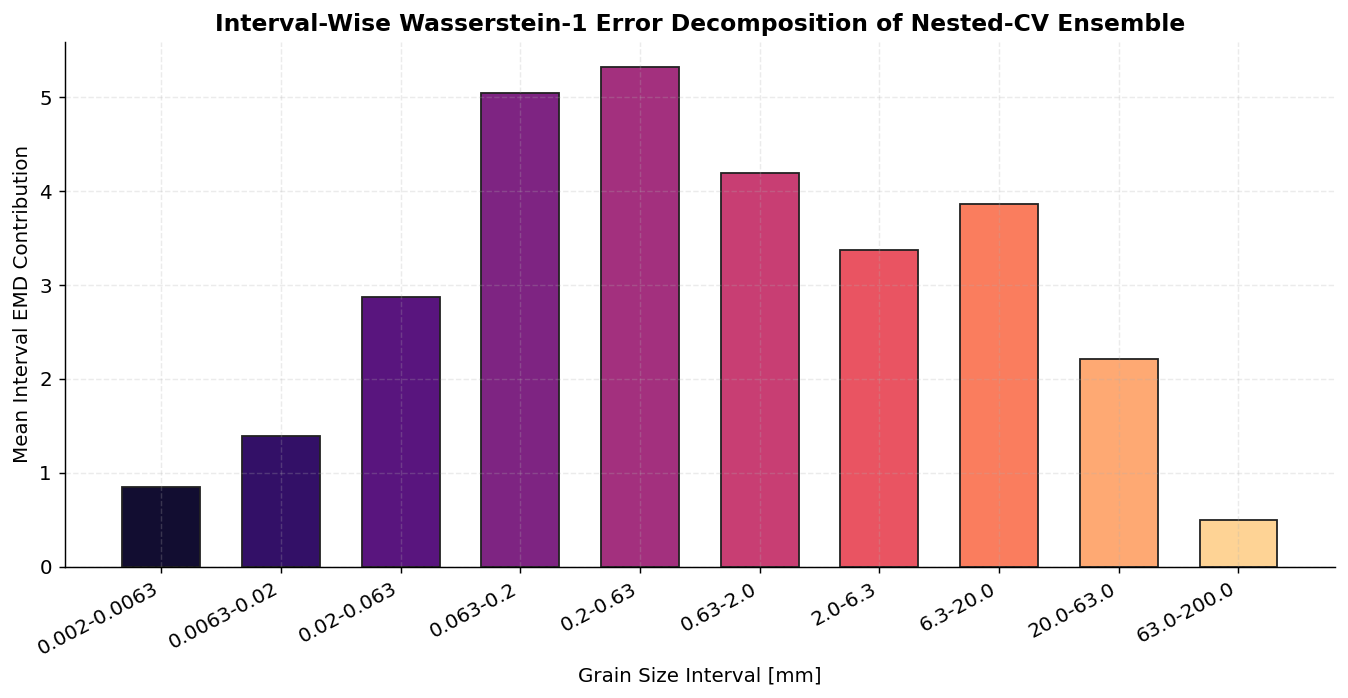

In [20]:
interval_errors = np.mean(np.abs(Y_train[:, :10] - nested_oof[:, :10]) * INTERVAL_WEIGHTS[None, :], axis=0)
fig, ax = plt.subplots(figsize=(10.5, 5.5))
colors_int = sns.color_palette("magma", n_colors=10)
ax.bar(bin_labels, interval_errors, color=colors_int, edgecolor="#222222", width=0.65)
ax.set_xticklabels(bin_labels, rotation=28, ha="right")
ax.set_xlabel("Grain Size Interval [mm]")
ax.set_ylabel("Mean Interval EMD Contribution")
ax.set_title("Interval-Wise Wasserstein-1 Error Decomposition of Nested-CV Ensemble")
plt.tight_layout()
plt.show()

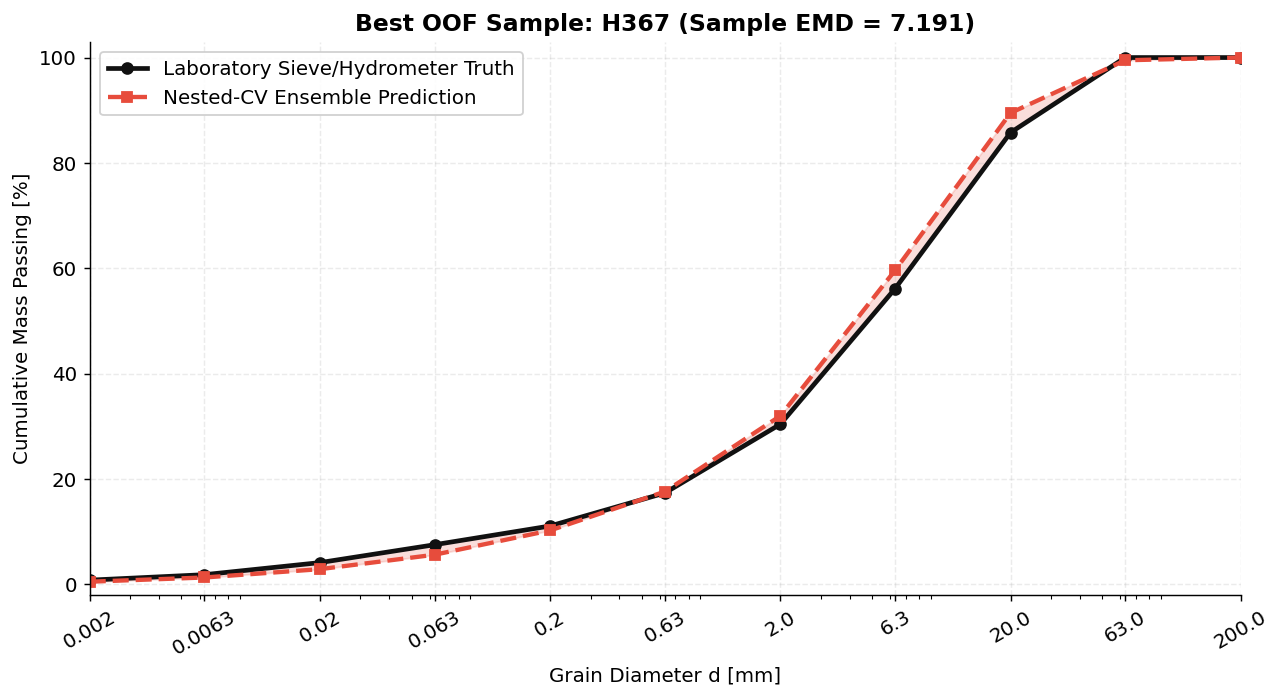

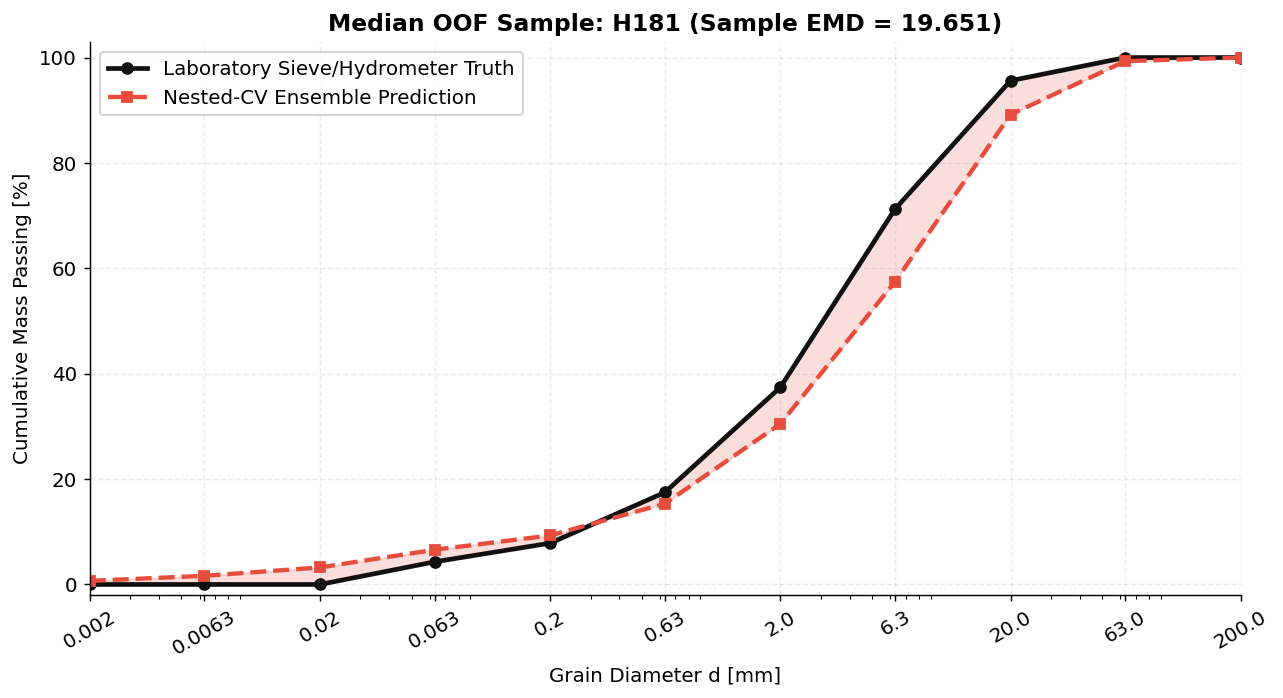

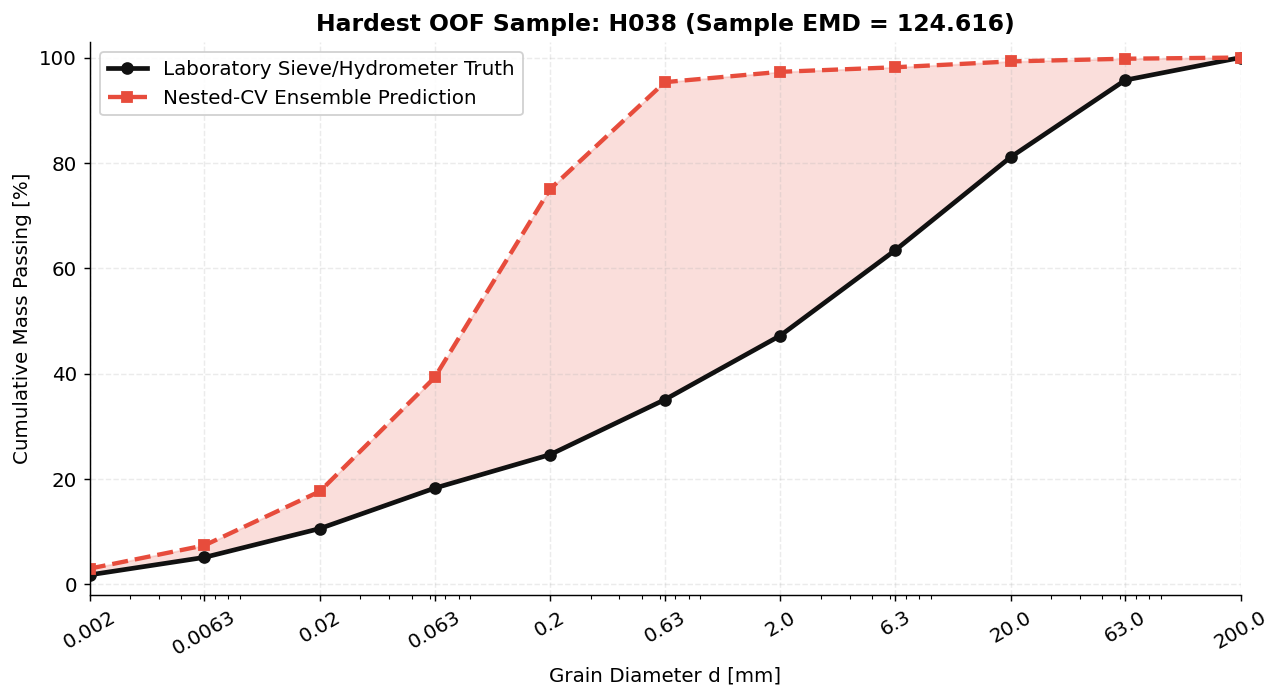

In [21]:
sample_emds = np.array([compute_emd_sample(Y_train[i], nested_oof[i]) for i in range(len(Y_train))])
best_idx = np.argmin(sample_emds)
median_idx = np.argsort(sample_emds)[len(sample_emds) // 2]
worst_idx = np.argmax(sample_emds)

for tag, idx in [("Best OOF Sample", best_idx), ("Median OOF Sample", median_idx), ("Hardest OOF Sample", worst_idx)]:
    fig, ax = plt.subplots(figsize=(10.0, 5.5))
    ax.plot(DIAMETERS, Y_train[idx], "o-", color="#111111", linewidth=2.6, markersize=6, label="Laboratory Sieve/Hydrometer Truth")
    ax.plot(DIAMETERS, nested_oof[idx], "s--", color="#e74c3c", linewidth=2.4, markersize=6, label="Nested-CV Ensemble Prediction")
    ax.fill_between(DIAMETERS, Y_train[idx], nested_oof[idx], color="#e74c3c", alpha=0.18)
    ax.set_xscale("log")
    ax.set_xlim(0.002, 200.0)
    ax.set_ylim(-2, 103)
    ax.set_xticks(DIAMETERS)
    ax.set_xticklabels([str(x) for x in DIAMETERS], rotation=30)
    ax.set_xlabel("Grain Diameter d [mm]")
    ax.set_ylabel("Cumulative Mass Passing [%]")
    ax.set_title(f"{tag}: {train_df.loc[idx, 'sample_id']} (Sample EMD = {sample_emds[idx]:.3f})")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

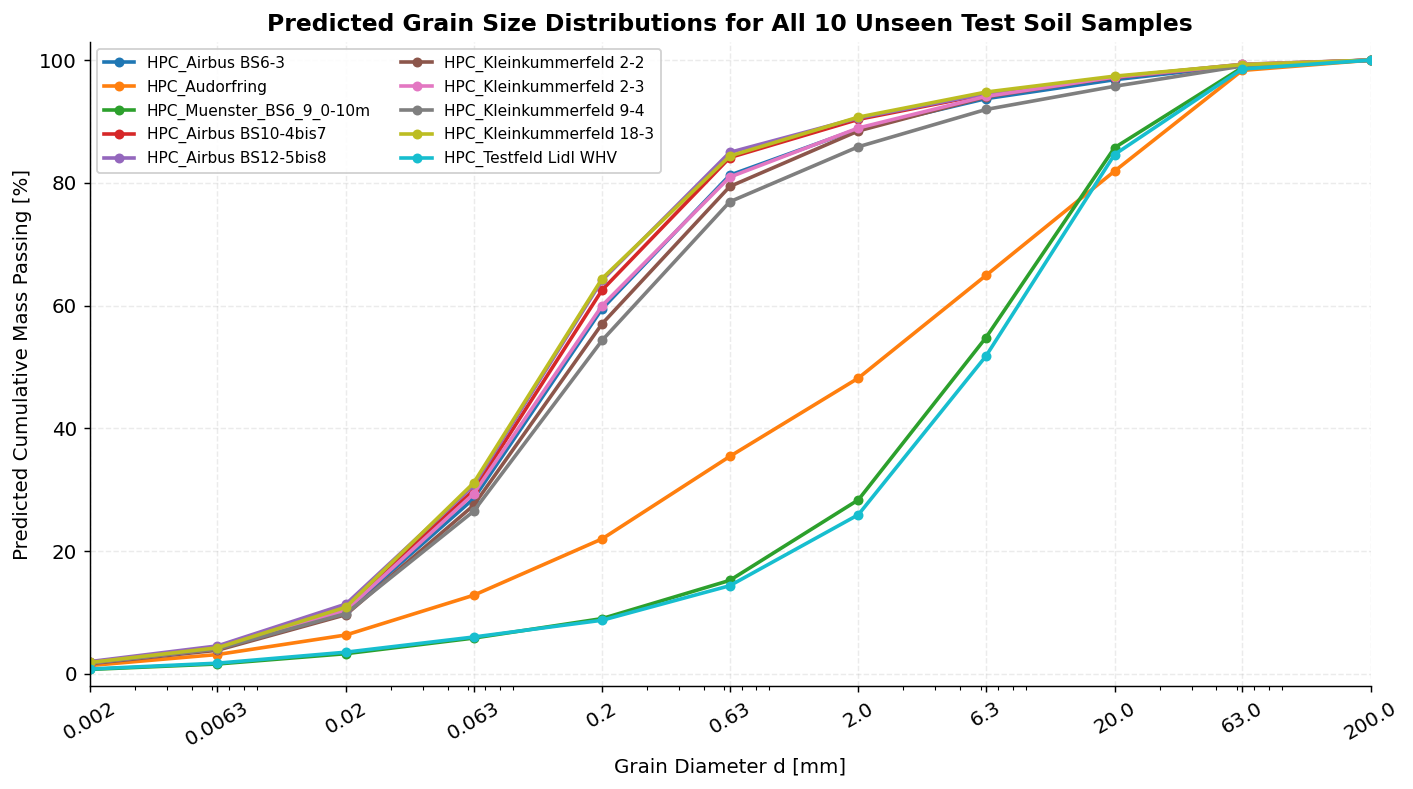

In [22]:
fig, ax = plt.subplots(figsize=(11, 6.2))
test_pal = plt.cm.tab10(np.linspace(0, 1, len(sub_df)))
for j in range(len(sub_df)):
    ax.plot(DIAMETERS, final_test_preds[j], "o-", color=test_pal[j], linewidth=2.0, markersize=4.5, label=sub_df.loc[j, "sample_id"])
ax.set_xscale("log")
ax.set_xlim(0.002, 200.0)
ax.set_ylim(-2, 103)
ax.set_xticks(DIAMETERS)
ax.set_xticklabels([str(x) for x in DIAMETERS], rotation=30)
ax.set_xlabel("Grain Diameter d [mm]")
ax.set_ylabel("Predicted Cumulative Mass Passing [%]")
ax.set_title("Predicted Grain Size Distributions for All 10 Unseen Test Soil Samples")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
plt.tight_layout()
plt.show()

# 12. Submission Generation and Structural Verification

We construct `submission.csv` matching `sample_submission.csv` and verify all competition constraints: exact row count, exact column headers, no NaN/Inf values, bounds $[0, 100]$, strict non-decreasing monotonicity across the 11 support points, and $F(200\text{ mm}) = 100.0$.

In [23]:
sub_out = sub_df.copy()
sub_out[TARGET_COLS] = np.round(final_test_preds, 6)
sub_out["200"] = 100.0

assert list(sub_out.columns) == list(sub_df.columns), "Column mismatch"
assert len(sub_out) == len(sub_df), "Row count mismatch"
vals = sub_out[TARGET_COLS].values
assert not np.isnan(vals).any(), "NaN values detected"
assert np.all((vals >= 0.0) & (vals <= 100.0)), "Values out of [0, 100] range"
assert np.all(np.diff(vals, axis=1) >= -1e-9), "Monotonicity violation detected"
assert np.allclose(vals[:, -1], 100.0), "Final 200 mm column must equal 100.0"

sub_out.to_csv("submission.csv", index=False)
print("Saved submission.csv successfully. All structural assertions passed.")
display(sub_out)

Saved submission.csv successfully. All structural assertions passed.


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,1.755055,4.060372,10.158459,28.526120,59.487272,81.252853,88.818389,93.720858,96.809660,99.154368,100.0
1,HPC_Audorfring,1.332033,3.129277,6.314410,12.784517,21.978491,35.417851,48.183435,64.916110,81.907644,98.323381,100.0
2,HPC_Muenster_BS6_9_0-10m,0.702782,1.586641,3.266657,5.808442,8.987053,15.215595,28.335956,54.792532,85.726571,98.789688,100.0
3,HPC_Airbus BS10-4bis7,1.870702,4.318540,10.889199,29.886917,62.538729,84.126555,90.345849,94.444640,97.165460,99.224271,100.0
4,HPC_Airbus BS12-5bis8,1.973137,4.531673,11.351828,30.680303,64.128019,84.968918,90.571052,94.531375,97.197393,99.184268,100.0
5,HPC_Kleinkummerfeld 2-2,1.639843,3.828454,9.622843,27.435593,57.043923,79.407721,88.458895,94.003433,97.244762,99.321661,100.0
6,HPC_Kleinkummerfeld 2-3,1.765076,4.081102,10.317354,29.314780,59.992504,80.942931,88.944024,94.089316,97.243432,99.292794,100.0
7,HPC_Kleinkummerfeld 9-4,1.747541,4.025818,9.803830,26.478973,54.335662,76.921380,85.883478,91.960897,95.739373,99.032775,100.0
8,HPC_Kleinkummerfeld 18-3,1.829760,4.229856,10.855688,31.083589,64.407530,84.373446,90.713396,94.797928,97.391417,99.273285,100.0
9,HPC_Testfeld Lidl WHV,0.765949,1.718074,3.511170,5.982072,8.717414,14.346601,25.913449,51.773133,84.616103,98.556240,100.0
